
# GEI723 — Problème 1 : Locomotion hexapodale


$[
\text{distance obstacle}
\rightarrow
\text{neurones sensoriels}
\rightarrow
\text{neurones centraux}
\rightarrow
\text{neurones prémoteurs antagonistes}
\rightarrow
\text{motoneurones}
]$


### Idée principale

- un **CPG local par patte** détermine **quand** la patte doit recevoir une commande ;
- les CPG sont coordonnés par des connexions excitatrices/inhibitrices locales ;
- chaque CPG excite deux neurones prémoteurs : un `PM-F` et un `PM-B` ;
  ils **excitent la voie prémotrice voulue et inhibent la voie antagoniste** ;
- les deux neurones prémoteurs d'une même patte s'inhibent réciproquement ;
- seuls les neurones prémoteurs qui reçoivent à la fois le rythme CPG et le contexte central
  atteignent facilement leur seuil ;
- les neurones prémoteurs activent ensuite les motoneurones `F-*` ou `B-*`.


In [1]:

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from brian2 import (
    NeuronGroup, Synapses, SpikeMonitor, StateMonitor,
    TimedArray, start_scope, defaultclock, run, seed,
    ms, second, Hz
)


RESULTS_DIR = Path("results_hexapod")
RESULTS_DIR.mkdir(exist_ok=True)

RANDOM_SEED = 7

# Paramètres des CPG
TAU_M = 200 * ms
REFRACTORY = 40 * ms

# Couplage entre CPG
W_EXC_BASE = 0.055
W_INH_BASE = 0.160
SYNAPTIC_DELAY = 4 * ms

# Paramètres de la couche prémotrice (remplace les gates)
PREMOTOR_TAU_M = 20 * ms
PREMOTOR_TAU_CMD = 250 * ms
PREMOTOR_TAU_TURN = 120 * ms

# Un spike CPG seul reste sous le seuil du prémoteur.
W_CPG_TO_PREMOTOR = 0.75

# Les neurones centraux fournissent un contexte excitateur/inhibiteur lent.
W_DECISION_TO_PREMOTOR_EXC = 0.30
W_DECISION_TO_PREMOTOR_INH = 0.45

# Compétition entre les deux voies antagonistes d'une même patte.
W_PREMOTOR_RECIP_INH = 0.65

# Un spike prémoteur déclenche le motoneurone correspondant.
W_PREMOTOR_TO_MOTOR = 1.20

# En Partie I, la direction imposée est représentée par un biais descendant subthreshold.
PART1_PREMOTOR_BIAS = 0.35

print("Environnement prêt.")


Environnement prêt.


# 1. Fonctions de base du réseau

Pour **\(n\) paires de pattes**, les neurones CPG sont organisés dans l'ordre suivant :

$$
L_1,\;L_2,\;\ldots,\;L_n,\qquad
R_1,\;R_2,\;\ldots,\;R_n
$$

où :

- \($L_i$\) désigne la patte gauche numéro \(i\) ;
- \($R_i$\) désigne la patte droite numéro \(i\).

Pour **3 paires de pattes**, on obtient donc :

$$
L_1,\;L_2,\;L_3,\qquad R_1,\;R_2,\;R_3
$$

Les pattes sont ensuite réparties en deux groupes alternants :

$$
\boxed{A=\{L_1,\;R_2,\;L_3\}}
$$

$$
\boxed{B=\{R_1,\;L_2,\;R_3\}}
$$

Le **groupe A** démarre avec un potentiel membranaire plus proche du seuil que le **groupe B**.  
Cela permet de briser la symétrie initiale et de faire commencer le groupe A en premier.

Ensuite, les connexions excitatrices et inhibitrices entre les CPG permettent de maintenir la coordination entre les deux groupes :

$$
A \;\longrightarrow\; B \;\longrightarrow\; A \;\longrightarrow\; B \;\longrightarrow\;\cdots
$$


In [7]:

def leg_names(n_pairs):
    left = [f"L{k+1}" for k in range(n_pairs)]
    right = [f"R{k+1}" for k in range(n_pairs)]
    return left + right


def tripod_groups(n_pairs):
    # Alternance A/B sur le côté gauche.
    left = np.arange(n_pairs) % 2

    # Le côté droit est déphasé d'un groupe.
    right = 1 - left

    # 0 = groupe A ; 1 = groupe B
    return np.concatenate([left, right]).astype(int)


def target_frequency_to_drive(freq_hz):
    """
    Convertit une fréquence propre souhaitée en courant I_drive
    pour le neurone LIF utilisé comme oscillateur tonique.

    Avec :
        dv/dt = (I - v)/tau
        seuil = 1
        reset = 0
        refractory = REFRACTORY

    La période est :
        T = refractory + tau * ln(I/(I-1))
    """
    f = float(freq_hz)
    if f <= 0:
        raise ValueError("La fréquence doit être strictement positive.")

    T = (1.0 / f) * second
    active_time = T - REFRACTORY

    if active_time <= 0 * second:
        raise ValueError(
            "Fréquence trop élevée par rapport à la période réfractaire."
        )

    x = float(active_time / TAU_M)
    return 1.0 / (1.0 - np.exp(-x))


def local_coupling_edges(n_pairs):
    """
    Construit un couplage distribué/local entre CPG.

    Connexions considérées :
    - voisins et seconds voisins sur un même côté ;
    - pattes controlatérales de même rang ;
    - diagonales entre rangs voisins.

    Si deux pattes appartiennent au même groupe A/B :
        connexion excitatrice.
    Sinon :
        connexion inhibitrice.

    Les connexions sont bidirectionnelles.
    """
    groups = tripod_groups(n_pairs)

    exc = set()
    inh = set()

    def add_bidirectional(a, b):
        if a == b:
            return
        for src, dst in ((a, b), (b, a)):
            if groups[src] == groups[dst]:
                exc.add((src, dst))
            else:
                inh.add((src, dst))

    # Même côté : voisins et seconds voisins
    for start in (0, n_pairs):
        for k in range(n_pairs):
            for delta in (1, 2):
                if k + delta < n_pairs:
                    add_bidirectional(start + k, start + k + delta)

    # Controlatérales de même rang
    for k in range(n_pairs):
        add_bidirectional(k, n_pairs + k)

    # Diagonales entre rangs voisins
    for k in range(n_pairs - 1):
        add_bidirectional(k, n_pairs + k + 1)
        add_bidirectional(n_pairs + k, k + 1)

    exc = sorted(exc)
    inh = sorted(inh)

    exc_i = np.array([x[0] for x in exc], dtype=int)
    exc_j = np.array([x[1] for x in exc], dtype=int)
    inh_i = np.array([x[0] for x in inh], dtype=int)
    inh_j = np.array([x[1] for x in inh], dtype=int)

    return exc_i, exc_j, inh_i, inh_j


# 2. Encodage sensoriel de la distance

On souhaite que plus un obstacle est proche, plus la fréquence de décharge du neurone sensoriel soit élevée :

$$
d \downarrow
\quad \Rightarrow \quad
f_{\mathrm{sensoriel}} \uparrow
$$

La distance mesurée est d'abord convertie en une intensité normalisée :

$$
x
=
\mathrm{clip}
\left(
1-\frac{d}{d_{\max}},
0,
1
\right)
$$

avec :

- $d$ : distance mesurée jusqu'à l'obstacle ;
- $d_{\max}$ : distance maximale de détection ;
- $x$ : intensité normalisée comprise entre $0$ et $1$.

Cette intensité est ensuite convertie en fréquence de décharge :

$$
f_{\mathrm{sensoriel}}
=
x\,f_{\max}
$$

où $f_{\max}$ représente la fréquence sensorielle maximale.

Ainsi :

- obstacle hors de portée $\rightarrow 0\,\mathrm{Hz}$ ;
- obstacle éloigné $\rightarrow$ faible fréquence ;
- obstacle proche $\rightarrow$ fréquence élevée.


In [8]:

SENSOR_NAMES = ["S-LEFT", "S-FRONT", "S-RIGHT", "S-REAR"]
SENSOR_INDEX = {
    "left": 0,
    "front": 1,
    "right": 2,
    "rear": 3,
}


def distance_to_sensor_rate(
    distance_cm,
    detection_distance_cm=100.0,
    max_rate_hz=40.0,
):
    """Distance (cm) -> fréquence sensorielle (Hz)."""
    d = np.asarray(distance_cm, dtype=float)

    intensity = 1.0 - d / float(detection_distance_cm)
    intensity = np.clip(intensity, 0.0, 1.0)

    # np.inf devient naturellement une intensité nulle après clip.
    return float(max_rate_hz) * intensity


def build_distance_profile(
    duration,
    events=None,
    dt_sensor=0.01,
):
    """
    Construit les distances gauche/avant/droite/arrière au cours du temps.

    Un événement est un dictionnaire, par exemple :
        {
            "side": "right",
            "start": 2.0,
            "end": 4.0,
            "distance_cm": 25.0
        }

    On peut aussi simuler un obstacle qui se rapproche :
        {
            "side": "right",
            "start": 2.0,
            "end": 4.0,
            "distance_start_cm": 80.0,
            "distance_end_cm": 20.0
        }
    """
    duration = float(duration)
    dt_sensor = float(dt_sensor)

    n_steps = int(np.ceil(duration / dt_sensor)) + 1
    t = np.arange(n_steps) * dt_sensor

    # Colonnes : LEFT, FRONT, RIGHT, REAR
    distances = np.full((n_steps, 4), np.inf, dtype=float)

    if events is None:
        events = []

    for event in events:
        side = str(event["side"]).lower()
        if side not in SENSOR_INDEX:
            raise ValueError(
                f"Côté inconnu : {side}. "
                f"Utiliser {list(SENSOR_INDEX)}."
            )

        start = float(event["start"])
        end = float(event["end"])

        if end <= start:
            raise ValueError("La fin d'un événement doit être après son début.")

        idx = SENSOR_INDEX[side]
        mask = (t >= start) & (t < end)

        if "distance_cm" in event:
            values = np.full(mask.sum(), float(event["distance_cm"]))
        else:
            d0 = float(event["distance_start_cm"])
            d1 = float(event["distance_end_cm"])
            alpha = (t[mask] - start) / (end - start)
            values = d0 + alpha * (d1 - d0)

        # Si plusieurs événements se superposent sur un même capteur,
        # on conserve l'obstacle le plus proche.
        distances[mask, idx] = np.minimum(
            distances[mask, idx],
            values,
        )

    return t, distances


# 3. Architecture pseudo-autonome
## Niveau sensoriel

Le réseau possède quatre neurones sensoriels :

- `S-LEFT`
- `S-FRONT`
- `S-RIGHT`
- `S-REAR`

Leur fréquence de décharge code la proximité du stimulus : plus un obstacle est proche, plus le neurone sensoriel correspondant spike rapidement.

## Niveau central

Le réseau possède cinq neurones centraux de commande :

- `FORWARD`
- `BACKWARD`
- `TURN_LEFT`
- `TURN_RIGHT`
- `ACCELERATE`

Les connexions entre les neurones sensoriels et les neurones centraux sont :

$$
S_{\mathrm{RIGHT}}
\rightarrow
\mathrm{TURN\_LEFT}
$$

$$
S_{\mathrm{LEFT}}
\rightarrow
\mathrm{TURN\_RIGHT}
$$

$$
S_{\mathrm{FRONT}}
\rightarrow
\mathrm{BACKWARD}
$$

$$
S_{\mathrm{REAR}}
\rightarrow
\mathrm{ACCELERATE}
$$

Le neurone sensoriel frontal inhibe également le neurone `FORWARD` :

$$
S_{\mathrm{FRONT}}
\dashv
\mathrm{FORWARD}
$$

Ainsi, lorsqu'un obstacle apparaît devant l'hexapode, le réseau favorise la marche arrière tout en inhibant la marche avant.

---

## Couche prémotrice

Pour chaque patte $i$, deux neurones prémoteurs sont utilisés :

$$
PM_{F,i}
\qquad\text{et}\qquad
PM_{B,i}
$$

avec :

- $PM_{F,i}$ : neurone prémoteur associé à la marche avant ;
- $PM_{B,i}$ : neurone prémoteur associé à la marche arrière.

Le CPG associé à la patte $i$ excite les deux voies prémotrices :

$$
CPG_i
\rightarrow
PM_{F,i}
$$

$$
CPG_i
\rightarrow
PM_{B,i}
$$

Le spike du CPG indique donc **quand la patte peut recevoir une commande**, mais il ne détermine pas à lui seul si cette commande sera Forward ou Backward.

---

## Sélection Forward / Backward

Le neurone central `FORWARD` favorise les prémoteurs Forward et inhibe les prémoteurs Backward :

$$
\mathrm{FORWARD}
\rightarrow
PM_F
$$

$$
\mathrm{FORWARD}
\dashv
PM_B
$$

Inversement, le neurone central `BACKWARD` favorise les prémoteurs Backward et inhibe les prémoteurs Forward :

$$
\mathrm{BACKWARD}
\rightarrow
PM_B
$$

$$
\mathrm{BACKWARD}
\dashv
PM_F
$$

Pour chaque patte $i$, les deux prémoteurs s'inhibent également réciproquement :

$$
PM_{F,i}
\dashv
PM_{B,i}
$$

$$
PM_{B,i}
\dashv
PM_{F,i}
$$

Cette inhibition réciproque limite l'activation simultanée des commandes Forward et Backward pour une même patte.

---

## Prémoteurs vers motoneurones

Chaque prémoteur excite ensuite le motoneurone correspondant :

$$
PM_{F,i}
\rightarrow
F_i
$$

$$
PM_{B,i}
\rightarrow
B_i
$$

---

## Interprétation

On peut résumer les rôles ainsi :

- le **CPG** détermine **quand** la patte doit agir ;
- les neurones `FORWARD` et `BACKWARD` déterminent **quelle direction est favorisée** ;
- les neurones prémoteurs effectuent la **sélection entre Forward et Backward** ;
- les motoneurones produisent la **commande finale de la patte**.

---


### Virage à gauche

Pour tourner à gauche, `TURN_LEFT` inhibe temporairement les prémoteurs Forward du côté gauche :

$$
\mathrm{TURN\_LEFT}
\dashv
PM_{F,\mathrm{gauche}}
$$

Les CPG gauches continuent donc à spiker normalement, mais une partie de leurs commandes est moins facilement transmise vers les motoneurones Forward.

### Virage à droite

Pour tourner à droite, `TURN_RIGHT` inhibe temporairement les prémoteurs Forward du côté droit :

$$
\mathrm{TURN\_RIGHT}
\dashv
PM_{F,\mathrm{droite}}
$$

Ainsi :

```text
Virage à droite

CPG gauche
    ↓
PM-F gauche
    ↓
commandes Forward conservées

CPG droit
    ↓
PM-F droit
    ↑
TURN_RIGHT inhibe cette voie
    ↓
moins de commandes Forward

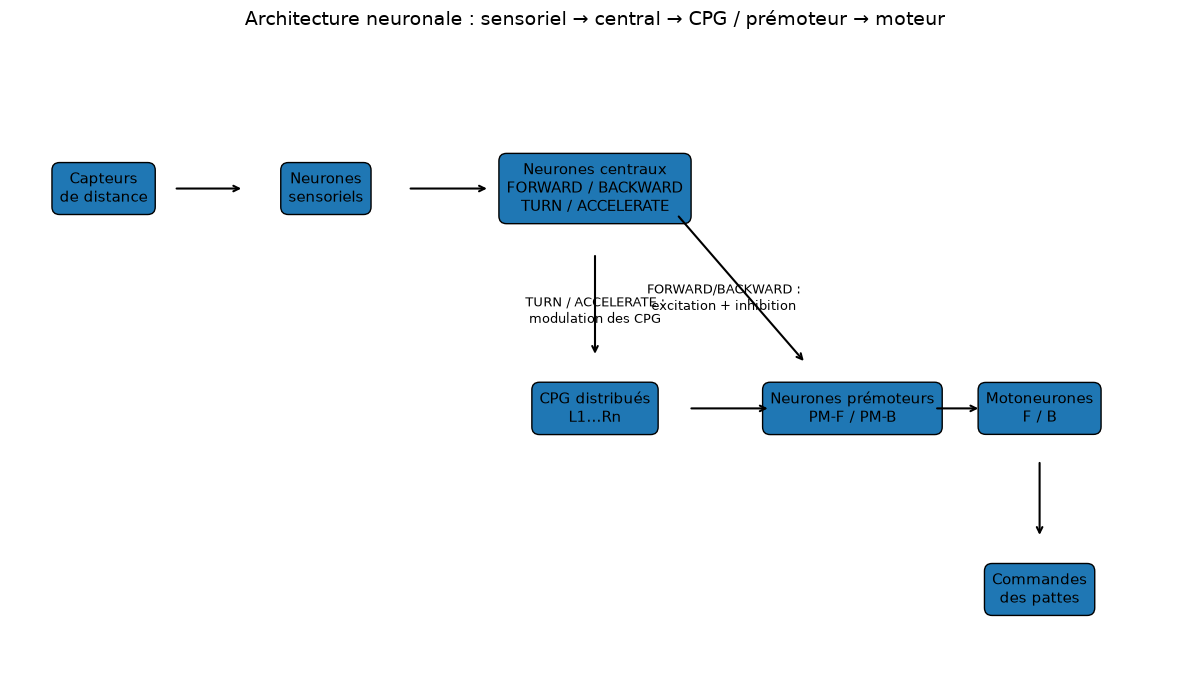

In [9]:

def plot_system_architecture(save=True):
    """Schéma bloc de l'architecture."""
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.axis("off")

    boxes = {
        "Capteurs\nde distance": (0.08, 0.76),
        "Neurones\nsensoriels": (0.27, 0.76),
        "Neurones centraux\nFORWARD / BACKWARD\nTURN / ACCELERATE": (0.50, 0.76),
        "CPG distribués\nL1...Rn": (0.50, 0.42),
        "Neurones prémoteurs\nPM-F / PM-B": (0.72, 0.42),
        "Motoneurones\nF / B": (0.88, 0.42),
        "Commandes\ndes pattes": (0.88, 0.14),
    }

    for label, (x, y) in boxes.items():
        ax.text(
            x, y, label,
            ha="center", va="center",
            fontsize=11,
            bbox=dict(boxstyle="round,pad=0.5"),
        )

    arrows = [
        ((0.14, 0.76), (0.20, 0.76)),
        ((0.34, 0.76), (0.41, 0.76)),
        ((0.50, 0.66), (0.50, 0.50)),   # décision -> CPG
        ((0.57, 0.72), (0.68, 0.49)),   # décision -> prémoteur
        ((0.58, 0.42), (0.65, 0.42)),   # CPG -> prémoteur
        ((0.79, 0.42), (0.83, 0.42)),   # prémoteur -> moteur
        ((0.88, 0.34), (0.88, 0.22)),
    ]

    for start, end in arrows:
        ax.annotate(
            "",
            xy=end, xytext=start,
            arrowprops=dict(arrowstyle="->", linewidth=1.5),
        )

    ax.text(
        0.61, 0.59,
        "FORWARD/BACKWARD :\nexcitation + inhibition",
        ha="center", va="center",
        fontsize=9,
    )

    ax.text(
        0.50, 0.57,
        "TURN / ACCELERATE :\nmodulation des CPG",
        ha="center", va="center",
        fontsize=9,
    )

    ax.set_title(
        "Architecture neuronale : sensoriel → central → CPG / prémoteur → moteur",
        fontsize=14,
    )

    plt.tight_layout()

    if save:
        plt.savefig(
            RESULTS_DIR / "00_architecture_systeme.png",
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()


plot_system_architecture()



# 4. Simulation complète

Cette fonction permet toujours deux modes.

### Partie I — non autonome

```python
sensor_control=False
```

La direction est imposée par un **biais descendant subthreshold** appliqué aux prémoteurs
Forward ou Backward du côté voulu.

Par exemple, pour avancer :

```text
CPG-L1 ───→ PM-F-L1 ───→ F-L1
      └───→ PM-B-L1
```

`PM-F-L1` reçoit un petit biais supplémentaire.  
Le spike CPG + ce biais suffisent à franchir le seuil ; la voie Backward reste sous le seuil.

### Partie II — pseudo-autonome

```python
sensor_control=True
```

Il n'y a pas de biais de direction imposé. Les neurones centraux font le travail :

```text
FORWARD  → excite PM-F
FORWARD  ─| inhibe PM-B

BACKWARD → excite PM-B
BACKWARD ─| inhibe PM-F
```

Les deux voies prémotrices d'une même patte s'inhibent également entre elles.

### Point important

Les connexions restent fixes pendant toute la simulation.  
Le passage Forward ↔ Backward vient seulement de l'activité des neurones centraux et
de la compétition synaptique entre les voies prémotrices.


In [32]:

def simulate_locomotion(
    n_pairs=3,
    duration=5.0,
    left_freq=2.0,
    right_freq=2.0,
    left_direction=+1,
    right_direction=+1,
    coupling_gain=1.0,
    
    turn_command=None,   # None, "left" ou "right"
    turn_drive=1.15,
    
    # Partie II
    sensor_control=False,
    sensor_events=None,
    detection_distance_cm=100.0,
    max_sensor_rate_hz=40.0,
    sensor_dt=0.01,

    # Intensité des modulations
    turn_step=0.18,
    accel_step=0.012,

    # Enregistrement des variables continues
    record_state=True,

    report=False,
):
    """
    Construit et simule le réseau complet.
    -----------------
    La sélection Forward / Backward est assurée par des neurones prémoteurs
    antagonistes et des synapses excitatrices/inhibitrices.

    Pour chaque patte :
        CPG_i -> PM-F_i -> F_i
        CPG_i -> PM-B_i -> B_i

    En Partie II :
        FORWARD  excite PM-F et inhibe PM-B.
        BACKWARD excite PM-B et inhibe PM-F.

    En Partie I :
        la direction imposée est représentée par un petit biais descendant
        subthreshold sur la population prémotrice choisie.
    """

    if not (1 <= int(n_pairs) <= 200):
        raise ValueError("n_pairs doit être compris entre 1 et 200.")

    if left_direction not in (-1, +1):
        raise ValueError("left_direction doit valoir +1 ou -1.")

    if right_direction not in (-1, +1):
        raise ValueError("right_direction doit valoir +1 ou -1.")

    start_scope()
    defaultclock.dt = 0.5 * ms
    seed(RANDOM_SEED)

    n_pairs = int(n_pairs)
    n_legs = 2 * n_pairs

    names = leg_names(n_pairs)
    groups = tripod_groups(n_pairs)

    # ============================================================
    # 1) CPG LOCAL DE CHAQUE PATTE
    # ============================================================

    eqs_cpg = """
    dv/dt = (I_base + I_mod - v) / tau_m : 1 (unless refractory)

    # Modulation transitoire des CPG venant seulement de ACCELERATE
    dI_mod/dt = -I_mod / (250*ms) : 1

    I_base : 1
    tau_m : second (constant)
    """

    cpg = NeuronGroup(
        n_legs,
        eqs_cpg,
        threshold="v >= 1",
        reset="v = 0",
        refractory=REFRACTORY,
        method="exact",
        name="cpg_local",
    )

    cpg.tau_m = TAU_M

    cpg.I_base[:n_pairs] = target_frequency_to_drive(left_freq)
    cpg.I_base[n_pairs:] = target_frequency_to_drive(right_freq)

    cpg.I_mod = 0

    # Groupe A proche du seuil, groupe B plus loin.
    cpg.v = np.where(groups == 0, 0.92, 0.08)

    # ============================================================
    # 2) COUPLAGE DISTRIBUÉ CPG <-> CPG
    # ============================================================

    exc_i, exc_j, inh_i, inh_j = local_coupling_edges(n_pairs)

    syn_exc = Synapses(
        cpg,
        cpg,
        model="w : 1",
        on_pre="v_post += w",
        name="syn_exc",
    )

    if len(exc_i):
        syn_exc.connect(i=exc_i, j=exc_j)
        syn_exc.w = W_EXC_BASE * coupling_gain
        syn_exc.delay = SYNAPTIC_DELAY

    syn_inh = Synapses(
        cpg,
        cpg,
        model="w : 1",
        on_pre="v_post -= w",
        name="syn_inh",
    )

    if len(inh_i):
        syn_inh.connect(i=inh_i, j=inh_j)
        syn_inh.w = W_INH_BASE * coupling_gain
        syn_inh.delay = SYNAPTIC_DELAY

    # ============================================================
    # 3) COUCHE PRÉMOTRICE : PM-F / PM-B
    # ============================================================
    #
    # 0 ... n_legs-1        = prémoteurs Forward
    # n_legs ... 2*n_legs-1 = prémoteurs Backward
    #
    # I_bias :
    #   biais descendant utilisé seulement pour la Partie I.
    #
    # I_cmd :
    #   influence lente de FORWARD/BACKWARD.
    #
    # I_turn :
    #   inhibition transitoire utilisée pour le virage.
    #   TURN_LEFT inhibe les prémoteurs Forward gauches.
    #   TURN_RIGHT inhibe les prémoteurs Forward droits.
    #
    # Un prémoteur Forward est donc contrôlé par :
    #   1) le timing du CPG
    #   2) le contexte Forward/Backward via I_cmd
    #   3) le contexte de virage via I_turn
    # ============================================================

    premotor = NeuronGroup(
        2 * n_legs,
        """
        dv/dt = (I_bias + I_cmd + I_turn - v) / tau_p : 1 (unless refractory)
        dI_cmd/dt = -I_cmd / tau_cmd : 1
        dI_turn/dt = -I_turn / tau_turn : 1

        I_bias : 1
        tau_p : second (constant)
        tau_cmd : second (constant)
        tau_turn : second (constant)
        """,
        threshold="v >= 1",
        reset="v = 0",
        refractory=5 * ms,
        method="exact",
        name="premotor_neurons",
    )

    premotor.v = 0
    premotor.I_cmd = 0
    premotor.I_turn = 0
    premotor.I_bias = 0

    premotor.tau_p = PREMOTOR_TAU_M
    premotor.tau_cmd = PREMOTOR_TAU_CMD
    premotor.tau_turn = PREMOTOR_TAU_TURN

    # ------------------------------------------------------------
    # Partie I : biais descendant imposé
    # ------------------------------------------------------------
    if not sensor_control:
        for i in range(n_legs):
            direction = (
                left_direction if i < n_pairs
                else right_direction
            )

            if direction == +1:
                premotor.I_bias[i] = PART1_PREMOTOR_BIAS
            else:
                premotor.I_bias[n_legs + i] = PART1_PREMOTOR_BIAS

    # ============================================================
    # 4) CHAQUE CPG -> LES DEUX VOIES PRÉMOTRICES
    # ============================================================
    #
    # Un spike CPG seul ajoute 0.75 :
    # il reste normalement sous le seuil (= 1).
    #
    # La voie favorisée par FORWARD/BACKWARD possède en plus
    # un contexte synaptique I_cmd : CPG + contexte -> spike.
    # ============================================================

    route_i = np.concatenate([
        np.arange(n_legs),
        np.arange(n_legs),
    ])

    route_j = np.concatenate([
        np.arange(n_legs),
        n_legs + np.arange(n_legs),
    ])

    cpg_to_premotor = Synapses(
        cpg,
        premotor,
        on_pre=f"v_post += {float(W_CPG_TO_PREMOTOR)}",
        name="cpg_to_premotor",
    )

    cpg_to_premotor.connect(
        i=route_i,
        j=route_j,
    )

    # ============================================================
    # 5) COMPÉTITION PRÉMOTRICE LOCALE F <-> B
    # ============================================================
    #
    # Pour chaque patte :
    # PM-F_i --| PM-B_i
    # PM-B_i --| PM-F_i
    #
    # Cela limite la coactivation antagoniste.
    # ============================================================

    pm_source = np.concatenate([
        np.arange(n_legs),
        n_legs + np.arange(n_legs),
    ])

    pm_target = np.concatenate([
        n_legs + np.arange(n_legs),
        np.arange(n_legs),
    ])

    premotor_reciprocal_inhibition = Synapses(
        premotor,
        premotor,
        on_pre=f"v_post -= {float(W_PREMOTOR_RECIP_INH)}",
        name="premotor_reciprocal_inhibition",
    )

    premotor_reciprocal_inhibition.connect(
        i=pm_source,
        j=pm_target,
    )

    # ============================================================
    # 6) NEURONES MOTEURS : FORWARD / BACKWARD
    # ============================================================
    #
    # Les motoneurones ne possèdent plus de variable gate.
    # Ils reçoivent uniquement les spikes du prémoteur correspondant.
    # ============================================================

    motor = NeuronGroup(
        2 * n_legs,
        """
        dv/dt = -v/(15*ms) : 1
        """,
        threshold="v >= 1",
        reset="v = 0",
        refractory=5 * ms,
        method="exact",
        name="motor_commands",
    )

    motor.v = 0

    premotor_to_motor = Synapses(
        premotor,
        motor,
        on_pre=f"v_post += {float(W_PREMOTOR_TO_MOTOR)}",
        name="premotor_to_motor",
    )

    premotor_to_motor.connect(
        i=np.arange(2 * n_legs),
        j=np.arange(2 * n_legs),
    )

    # ============================================================
    # 7) PROFIL SENSORIEL DYNAMIQUE
    # ============================================================

    profile_t, distance_profile = build_distance_profile(
        duration=duration,
        events=sensor_events if sensor_control else [],
        dt_sensor=sensor_dt,
    )

    rate_profile = distance_to_sensor_rate(
        distance_profile,
        detection_distance_cm=detection_distance_cm,
        max_rate_hz=max_sensor_rate_hz,
    )

    if not sensor_control:
        rate_profile[:] = 0.0

    sensor_rate_t = TimedArray(
        rate_profile * Hz,
        dt=float(sensor_dt) * second,
    )

    # ============================================================
    # 8) NEURONES SENSORIELS
    # ============================================================

    sensor = NeuronGroup(
        4,
        """
        dv/dt = sensor_rate_t(t, i) : 1
        """,
        threshold="v >= 1",
        reset="v = 0",
        method="euler",
        namespace={"sensor_rate_t": sensor_rate_t},
        name="sensor_neurons",
    )

    sensor.v = 0

    # ============================================================
    # 9) NEURONES CENTRAUX
    # ============================================================
    #
    # 0 = FORWARD
    # 1 = BACKWARD
    # 2 = TURN_LEFT
    # 3 = TURN_RIGHT
    # 4 = ACCELERATE
    # ============================================================

    decision_names = [
        "FORWARD",
        "BACKWARD",
        "TURN_LEFT",
        "TURN_RIGHT",
        "ACCELERATE",
    ]

    decision = NeuronGroup(
        5,
        """
        dv/dt = (I_tonic - v)/(100*ms) : 1 (unless refractory)
        I_tonic : 1
        """,
        threshold="v >= 1",
        reset="v = 0",
        refractory=20 * ms,
        method="exact",
        name="decision_neurons",
    )

    decision.v = 0
    decision.I_tonic = 0
    

    if sensor_control:
        # Partie II :
        # avance spontanée
        decision.I_tonic[0] = 1.25
    
    else:
        # Partie I :
        # possibilité d'imposer un virage
    
        if turn_command == "left":
            decision.I_tonic[2] = turn_drive
    
        elif turn_command == "right":
            decision.I_tonic[3] = turn_drive
    
        elif turn_command is not None:
            raise ValueError(
                'turn_command doit être None, "left" ou "right".'
            )

    # ============================================================
    # 10) CAPTEURS -> DÉCISION
    # ============================================================

    sensor_to_decision = Synapses(
        sensor,
        decision,
        model="w : 1",
        on_pre="v_post += w",
        name="sensor_to_decision",
    )

    sensor_to_decision.connect(
        i=np.array([0, 1, 2, 3]),
        j=np.array([3, 1, 2, 4]),
    )

    sensor_to_decision.w = 0.55

    # FRONT inhibe également FORWARD.
    front_inhibits_forward = Synapses(
        sensor,
        decision,
        on_pre="v_post -= 0.90",
        name="front_inhibits_forward",
    )

    front_inhibits_forward.connect(
        i=[1],
        j=[0],
    )

    # ============================================================
    # 11) COMPÉTITION ENTRE ORDRES CENTRAUX OPPOSÉS
    # ============================================================

    decision_inhibition = Synapses(
        decision,
        decision,
        model="w : 1",
        on_pre="v_post -= w",
        name="decision_inhibition",
    )

    decision_inhibition.connect(
        i=np.array([0, 1, 2, 3]),
        j=np.array([1, 0, 3, 2]),
    )

    decision_inhibition.w = np.array([
        0.25,  # FORWARD -> BACKWARD
        1.40,  # BACKWARD -> FORWARD
        0.80,  # TURN_LEFT -> TURN_RIGHT
        0.80,  # TURN_RIGHT -> TURN_LEFT
    ])

    # ============================================================
    # 12) FORWARD / BACKWARD -> PRÉMOTEURS
    # ============================================================
    #
    # FORWARD :
    #   excite PM-F
    #   inhibe PM-B
    #
    # BACKWARD :
    #   excite PM-B
    #   inhibe PM-F
    #
    # On modifie I_cmd, qui décroît ensuite progressivement.
    # Il n'y a aucun changement binaire de l'état du réseau.
    # ============================================================

    forward_excites_pm_f = Synapses(
        decision,
        premotor,
        on_pre=f"I_cmd_post += {float(W_DECISION_TO_PREMOTOR_EXC)}",
        name="forward_excites_pm_f",
    )
    forward_excites_pm_f.connect(
        i=np.zeros(n_legs, dtype=int),
        j=np.arange(n_legs),
    )

    forward_inhibits_pm_b = Synapses(
        decision,
        premotor,
        on_pre=f"I_cmd_post -= {float(W_DECISION_TO_PREMOTOR_INH)}",
        name="forward_inhibits_pm_b",
    )
    forward_inhibits_pm_b.connect(
        i=np.zeros(n_legs, dtype=int),
        j=n_legs + np.arange(n_legs),
    )

    backward_excites_pm_b = Synapses(
        decision,
        premotor,
        on_pre=f"I_cmd_post += {float(W_DECISION_TO_PREMOTOR_EXC)}",
        name="backward_excites_pm_b",
    )
    backward_excites_pm_b.connect(
        i=np.ones(n_legs, dtype=int),
        j=n_legs + np.arange(n_legs),
    )

    backward_inhibits_pm_f = Synapses(
        decision,
        premotor,
        on_pre=f"I_cmd_post -= {float(W_DECISION_TO_PREMOTOR_INH)}",
        name="backward_inhibits_pm_f",
    )
    backward_inhibits_pm_f.connect(
        i=np.ones(n_legs, dtype=int),
        j=np.arange(n_legs),
    )

    # ============================================================
    # 13) TURN_LEFT / TURN_RIGHT -> PRÉMOTEURS FORWARD
    # ============================================================
    #
    # IMPORTANT :
    # Les neurones de virage ne modifient plus la fréquence des CPG.
    #
    # TURN_LEFT :
    #   inhibe les prémoteurs Forward du côté gauche.
    #   Les CPG continuent à spiker au même rythme,
    #   mais certaines commandes Forward gauches ne franchissent plus
    #   le seuil prémoteur.
    #
    # TURN_RIGHT :
    #   inhibe les prémoteurs Forward du côté droit.
    #
    # Cette inhibition agit sur I_turn, qui revient ensuite
    # progressivement vers 0.
    # ============================================================

    turn_left_inhibits_left_pm_f = Synapses(
        decision,
        premotor,
        on_pre=f"I_turn_post -= {float(turn_step)}",
        name="turn_left_inhibits_left_pm_f",
    )

    turn_left_inhibits_left_pm_f.connect(
        i=np.full(n_pairs, 2, dtype=int),   # TURN_LEFT
        j=np.arange(n_pairs),               # PM-F-L1 ... PM-F-Ln
    )

    turn_right_inhibits_right_pm_f = Synapses(
        decision,
        premotor,
        on_pre=f"I_turn_post -= {float(turn_step)}",
        name="turn_right_inhibits_right_pm_f",
    )

    turn_right_inhibits_right_pm_f.connect(
        i=np.full(n_pairs, 3, dtype=int),   # TURN_RIGHT
        j=n_pairs + np.arange(n_pairs),     # PM-F-R1 ... PM-F-Rn
    )

    # ============================================================
    # 14) ACCELERATE -> TOUS LES CPG
    # ============================================================

    accelerate_to_cpg = Synapses(
        decision,
        cpg,
        on_pre=f"I_mod_post += {float(accel_step)}",
        name="accelerate_to_cpg",
    )
    accelerate_to_cpg.connect(
        i=np.full(n_legs, 4, dtype=int),
        j=np.arange(n_legs),
    )

    # ============================================================
    # 15) MONITEURS
    # ============================================================

    cpg_spikes = SpikeMonitor(
        cpg,
        name="cpg_spikes",
    )

    premotor_spikes = SpikeMonitor(
        premotor,
        name="premotor_spikes",
    )

    motor_spikes = SpikeMonitor(
        motor,
        name="motor_spikes",
    )

    sensor_spikes = SpikeMonitor(
        sensor,
        name="sensor_spikes",
    )

    decision_spikes = SpikeMonitor(
        decision,
        name="decision_spikes",
    )

    premotor_state_monitor = None
    imod_monitor = None

    if record_state:
        premotor_state_monitor = StateMonitor(
            premotor,
            ["I_cmd", "I_turn", "v"],
            record=True,
            dt=10 * ms,
            name="premotor_state_monitor",
        )

        imod_monitor = StateMonitor(
            cpg,
            "I_mod",
            record=True,
            dt=10 * ms,
            name="imod_monitor",
        )

    # ============================================================
    # 16) SIMULATION
    # ============================================================

    t0 = time.perf_counter()

    run(
        float(duration) * second,
        report="text" if report else None,
    )

    elapsed = time.perf_counter() - t0

    premotor_names = (
        [f"PM-F-{x}" for x in names]
        +
        [f"PM-B-{x}" for x in names]
    )

    motor_names = (
        [f"F-{x}" for x in names]
        +
        [f"B-{x}" for x in names]
    )

    # ============================================================
    # 17) RÉSULTATS
    # ============================================================

    result = {
        "n_pairs": n_pairs,
        "n_legs": n_legs,
        "duration": float(duration),

        "left_freq_target": float(left_freq),
        "right_freq_target": float(right_freq),

        "left_direction_initial": int(left_direction),
        "right_direction_initial": int(right_direction),

        "coupling_gain": float(coupling_gain),

        "leg_names": names,
        "premotor_names": premotor_names,
        "motor_names": motor_names,
        "groups": groups.copy(),

        # CPG
        "cpg_t": np.asarray(cpg_spikes.t / second),
        "cpg_i": np.asarray(cpg_spikes.i, dtype=int),

        # Prémoteurs
        "premotor_t": np.asarray(premotor_spikes.t / second),
        "premotor_i": np.asarray(premotor_spikes.i, dtype=int),

        # Moteurs
        "motor_t": np.asarray(motor_spikes.t / second),
        "motor_i": np.asarray(motor_spikes.i, dtype=int),

        # Sensoriel
        "sensor_names": SENSOR_NAMES.copy(),
        "sensor_profile_t": profile_t,
        "distance_profile_cm": distance_profile.copy(),
        "sensor_rate_profile_hz": rate_profile.copy(),
        "sensor_t": np.asarray(sensor_spikes.t / second),
        "sensor_i": np.asarray(sensor_spikes.i, dtype=int),

        # Décision
        "decision_names": decision_names,
        "decision_t": np.asarray(decision_spikes.t / second),
        "decision_i": np.asarray(decision_spikes.i, dtype=int),

        # Performance / structure
        "elapsed_seconds": elapsed,
        "n_exc_synapses": len(exc_i),
        "n_inh_synapses": len(inh_i),
        "n_premotor_neurons": 2 * n_legs,
    }

    if premotor_state_monitor is not None:
        result["premotor_state_t"] = np.asarray(
            premotor_state_monitor.t / second
        )

        result["premotor_cmd"] = np.asarray(
            premotor_state_monitor.I_cmd
        )

        result["premotor_turn"] = np.asarray(
            premotor_state_monitor.I_turn
        )

        result["premotor_v"] = np.asarray(
            premotor_state_monitor.v
        )

    if imod_monitor is not None:
        result["imod_t"] = np.asarray(
            imod_monitor.t / second
        )

        result["imod"] = np.asarray(
            imod_monitor.I_mod
        )

    return result



# 5. Fonctions d'analyse et de visualisation


Chaque fonction :

- possède un titre ;
- possède des axes nommés ;
- possède une légende lorsque nécessaire ;
- peut sauvegarder automatiquement une image PNG dans `results_hexapod/`.


In [40]:

def _save_current_figure(filename, save):
    if save:
        plt.savefig(
            RESULTS_DIR / filename,
            dpi=200,
            bbox_inches="tight",
        )


def plot_cpg_raster(result, title="Activité des CPG", save_name=None):
    plt.figure(figsize=(11, 5))
    plt.scatter(
        result["cpg_t"],
        result["cpg_i"],
        s=18,
    )

    plt.yticks(
        np.arange(result["n_legs"]),
        result["leg_names"],
    )

    plt.xlabel("Temps (s)")
    plt.ylabel("CPG de la patte")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "cpg_raster.png",
        save_name is not None,
    )
    plt.show()


def plot_motor_raster(result, title="Activité des neurones moteurs", save_name=None):
    plt.figure(figsize=(11, 6))
    plt.scatter(
        result["motor_t"],
        result["motor_i"],
        s=18,
    )

    plt.yticks(
        np.arange(2 * result["n_legs"]),
        result["motor_names"],
    )

    plt.xlabel("Temps (s)")
    plt.ylabel("Neurone moteur")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "motor_raster.png",
        save_name is not None,
    )
    plt.show()


def plot_sensor_distances(result, title="Distances mesurées par les capteurs", save_name=None):
    plt.figure(figsize=(11, 5))

    t = result["sensor_profile_t"]
    distances = result["distance_profile_cm"]

    # On remplace inf par NaN pour ne pas tracer de ligne hors détection.
    display = distances.copy()
    display[~np.isfinite(display)] = np.nan

    for i, name in enumerate(result["sensor_names"]):
        plt.plot(t, display[:, i], label=name)

    plt.xlabel("Temps (s)")
    plt.ylabel("Distance de l'obstacle (cm)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "sensor_distances.png",
        save_name is not None,
    )
    plt.show()


def plot_sensor_rates(result, title="Fréquence sensorielle imposée", save_name=None):
    plt.figure(figsize=(11, 5))

    t = result["sensor_profile_t"]
    rates = result["sensor_rate_profile_hz"]

    for i, name in enumerate(result["sensor_names"]):
        plt.plot(t, rates[:, i], label=name)

    plt.xlabel("Temps (s)")
    plt.ylabel("Fréquence sensorielle (Hz)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "sensor_rates.png",
        save_name is not None,
    )
    plt.show()


def plot_sensor_raster(result, title="Spikes des neurones sensoriels", save_name=None):
    plt.figure(figsize=(11, 4))

    plt.scatter(
        result["sensor_t"],
        result["sensor_i"],
        s=20,
    )

    plt.yticks(
        np.arange(4),
        result["sensor_names"],
    )

    plt.xlabel("Temps (s)")
    plt.ylabel("Neurone sensoriel")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "sensor_raster.png",
        save_name is not None,
    )
    plt.show()


def plot_decision_raster(result, title="Spikes des neurones centraux", save_name=None):
    plt.figure(figsize=(11, 5))

    plt.scatter(
        result["decision_t"],
        result["decision_i"],
        s=20,
    )

    plt.yticks(
        np.arange(len(result["decision_names"])),
        result["decision_names"],
    )

    plt.xlabel("Temps (s)")
    plt.ylabel("Neurone central")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "decision_raster.png",
        save_name is not None,
    )
    plt.show()


def plot_premotor_raster(
    result,
    title="Activité des neurones prémoteurs",
    save_name=None,
):
    plt.figure(figsize=(11, 6))

    plt.scatter(
        result["premotor_t"],
        result["premotor_i"],
        s=18,
    )

    plt.yticks(
        np.arange(2 * result["n_legs"]),
        result["premotor_names"],
    )

    plt.xlabel("Temps (s)")
    plt.ylabel("Neurone prémoteur")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "premotor_raster.png",
        save_name is not None,
    )
    plt.show()


def plot_premotor_selection(
    result,
    title="Sélection neuronale Forward / Backward",
    save_name=None,
):
    """
    Affiche le contexte synaptique lent I_cmd reçu par les deux
    populations prémotrices.

    Contrairement à une gate, il s'agit d'une variable continue
    issue de l'activité synaptique des neurones centraux.
    """
    if "premotor_cmd" not in result:
        raise ValueError(
            "Relancer la simulation avec record_state=True."
        )

    n = result["n_legs"]

    forward_cmd = result["premotor_cmd"][:n].mean(axis=0)
    backward_cmd = result["premotor_cmd"][n:].mean(axis=0)

    plt.figure(figsize=(11, 4))

    plt.plot(
        result["premotor_state_t"],
        forward_cmd,
        label="Prémoteurs Forward",
    )

    plt.plot(
        result["premotor_state_t"],
        backward_cmd,
        label="Prémoteurs Backward",
    )

    plt.axhline(0, linewidth=1)

    plt.xlabel("Temps (s)")
    plt.ylabel("Commande synaptique moyenne I_cmd")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "premotor_selection.png",
        save_name is not None,
    )

    plt.show()


def plot_premotor_turn_modulation(
    result,
    title="Inhibition prémotrice utilisée pour les virages",
    save_name=None,
):
    if "premotor_turn" not in result:
        raise ValueError(
            "Relancer la simulation avec record_state=True."
        )

    n_pairs = result["n_pairs"]
    n_legs = result["n_legs"]

    # On regarde seulement la population Forward.
    left_turn = result["premotor_turn"][:n_pairs].mean(axis=0)
    right_turn = result["premotor_turn"][n_pairs:n_legs].mean(axis=0)

    plt.figure(figsize=(11, 4))

    plt.plot(
        result["premotor_state_t"],
        left_turn,
        label="PM-F gauche",
    )

    plt.plot(
        result["premotor_state_t"],
        right_turn,
        label="PM-F droit",
    )

    plt.axhline(0, linewidth=1)
    plt.xlabel("Temps (s)")
    plt.ylabel("I_turn moyen")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "premotor_turn_modulation.png",
        save_name is not None,
    )

    plt.show()


def plot_forward_motor_raster(result, title="Raster des motoneurones Forward", save_name=None):
    """
    Affiche seulement les motoneurones Forward :
    F-L1 ... F-Ln puis F-R1 ... F-Rn
    """
    n_pairs = result["n_pairs"]
    n_legs = result["n_legs"]

    motor_t = result["motor_t"]
    motor_i = result["motor_i"]

    # On garde seulement les motoneurones Forward
    forward_mask = motor_i < n_legs
    t = motor_t[forward_mask]
    i = motor_i[forward_mask]

    labels = [f"F-L{k+1}" for k in range(n_pairs)] + [f"F-R{k+1}" for k in range(n_pairs)]

    plt.figure(figsize=(10, 4))
    plt.scatter(t, i, s=30)

    plt.yticks(np.arange(n_legs), labels)
    plt.xlabel("Temps (s)")
    plt.ylabel("Motoneurone Forward")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()

    if save_name is not None:
        plt.savefig(RESULTS_DIR / save_name, dpi=200, bbox_inches="tight")

    plt.show()


def plot_cpg_modulation(result, title="Modulation globale des CPG par ACCELERATE", save_name=None):
    if "imod" not in result:
        raise ValueError(
            "Relancer la simulation avec record_state=True."
        )

    n = result["n_pairs"]

    left_mod = result["imod"][:n].mean(axis=0)
    right_mod = result["imod"][n:].mean(axis=0)

    plt.figure(figsize=(11, 4))
    plt.plot(
        result["imod_t"],
        left_mod,
        label="CPG gauche",
    )
    plt.plot(
        result["imod_t"],
        right_mod,
        label="CPG droit",
    )

    plt.axhline(0, linewidth=1)
    plt.xlabel("Temps (s)")
    plt.ylabel("I_mod moyen")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    _save_current_figure(
        save_name or "cpg_modulation.png",
        save_name is not None,
    )
    plt.show()


def spike_rate_by_neuron(times, indices, n_neurons, duration, t_start=0.0, t_end=None):
    if t_end is None:
        t_end = float(duration)

    mask = (times >= t_start) & (times < t_end)
    window = float(t_end - t_start)

    counts = np.bincount(
        indices[mask],
        minlength=n_neurons,
    )

    return counts / window


def cpg_side_rates(result, t_start=0.0, t_end=None):
    rates = spike_rate_by_neuron(
        result["cpg_t"],
        result["cpg_i"],
        result["n_legs"],
        result["duration"],
        t_start=t_start,
        t_end=t_end,
    )

    n = result["n_pairs"]

    return {
        "left_hz": rates[:n].mean(),
        "right_hz": rates[n:].mean(),
    }


def motor_forward_side_rates(result, t_start=0.0, t_end=None):
    """
    Fréquence moyenne des motoneurones Forward gauche et droit.
    Contrairement aux CPG, cette mesure peut devenir asymétrique pendant un virage.
    """
    rates = spike_rate_by_neuron(
        result["motor_t"],
        result["motor_i"],
        2 * result["n_legs"],
        result["duration"],
        t_start=t_start,
        t_end=t_end,
    )

    n_pairs = result["n_pairs"]
    n_legs = result["n_legs"]

    return {
        "left_forward_hz": rates[:n_pairs].mean(),
        "right_forward_hz": rates[n_pairs:n_legs].mean(),
    }


def decision_rates(result, t_start=0.0, t_end=None):
    rates = spike_rate_by_neuron(
        result["decision_t"],
        result["decision_i"],
        len(result["decision_names"]),
        result["duration"],
        t_start=t_start,
        t_end=t_end,
    )

    return dict(
        zip(result["decision_names"], rates)
    )



# PARTIE I — Système non autonome

Les expériences suivantes démontrent :

1. marche avant en ligne droite ;
2. marche arrière ;
3. variation de vitesse ;
4. rotation sur place ;
5. déplacement en cercle.

Les capteurs sont désactivés dans cette partie.


## 6. Marche avant en ligne droite

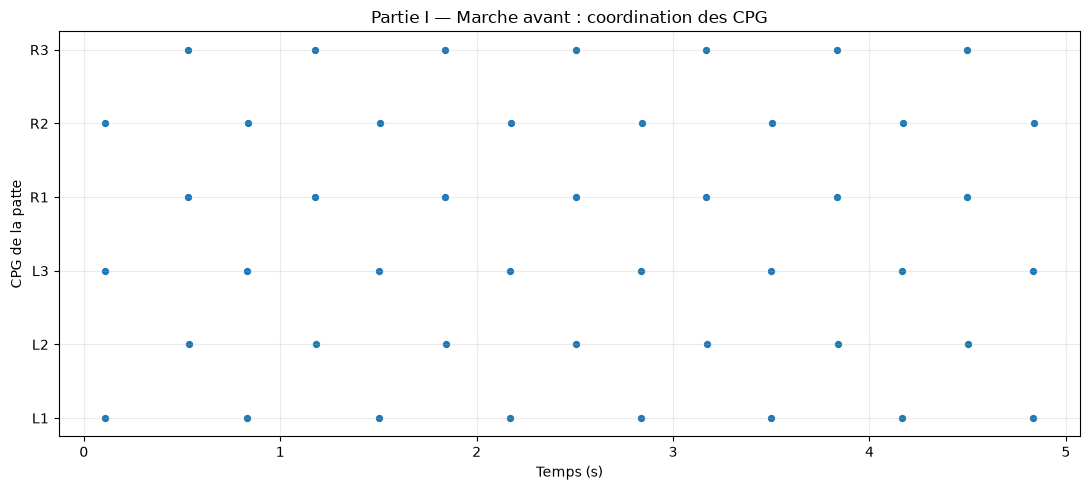

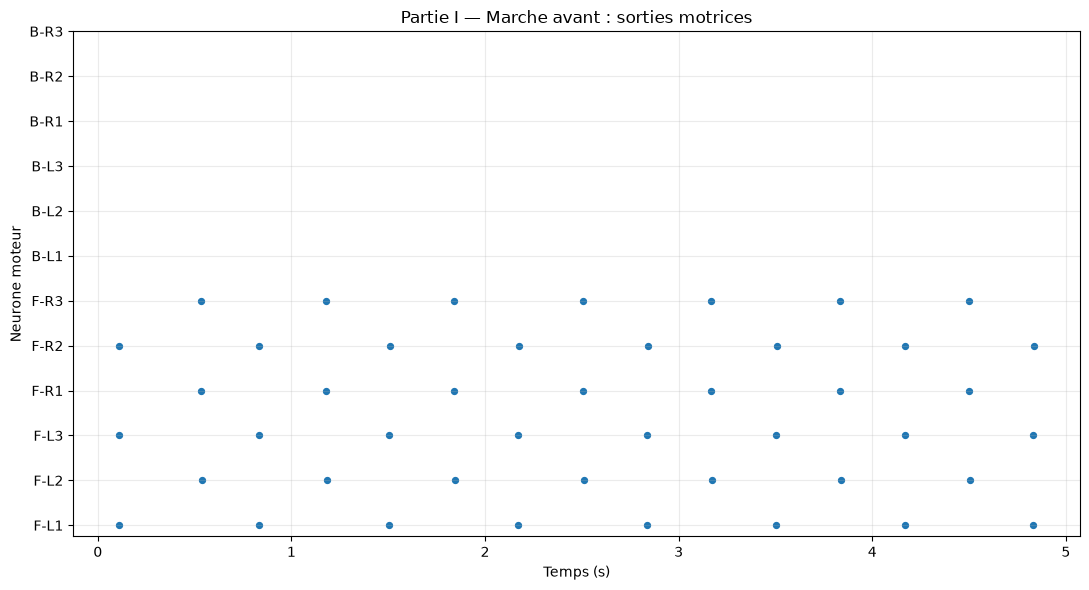

In [34]:

forward = simulate_locomotion(
    n_pairs=3,
    duration=5.0,
    left_freq=2.0,
    right_freq=2.0,
    left_direction=+1,
    right_direction=+1,
    sensor_control=False,
    record_state=False,
)

plot_cpg_raster(
    forward,
    title="Partie I — Marche avant : coordination des CPG",
    save_name="01_forward_cpg.png",
)

plot_motor_raster(
    forward,
    title="Partie I — Marche avant : sorties motrices",
    save_name="02_forward_motor.png",
)


Le graphe des CPG montre une activité périodique et coordonnée des six pattes. Les neurones appartenant aux deux groupes locomoteurs alternent leur activité, ce qui permet de conserver le rythme de marche de type tripod.

Au niveau moteur, seuls les motoneurones `Forward` déchargent, tandis que les motoneurones `Backward` restent silencieux. Les spikes moteurs suivent le rythme imposé par les CPG.

Ce résultat confirme donc que le réseau permet de produire une marche avant coordonnée :

$$
CPG
\rightarrow
PM_F
\rightarrow
F
$$

La sélection de la direction n'altère pas le rythme des CPG : ceux-ci déterminent les instants de commande, tandis que la voie prémotrice Forward sélectionne la direction du mouvement.

## 7. Marche arrière

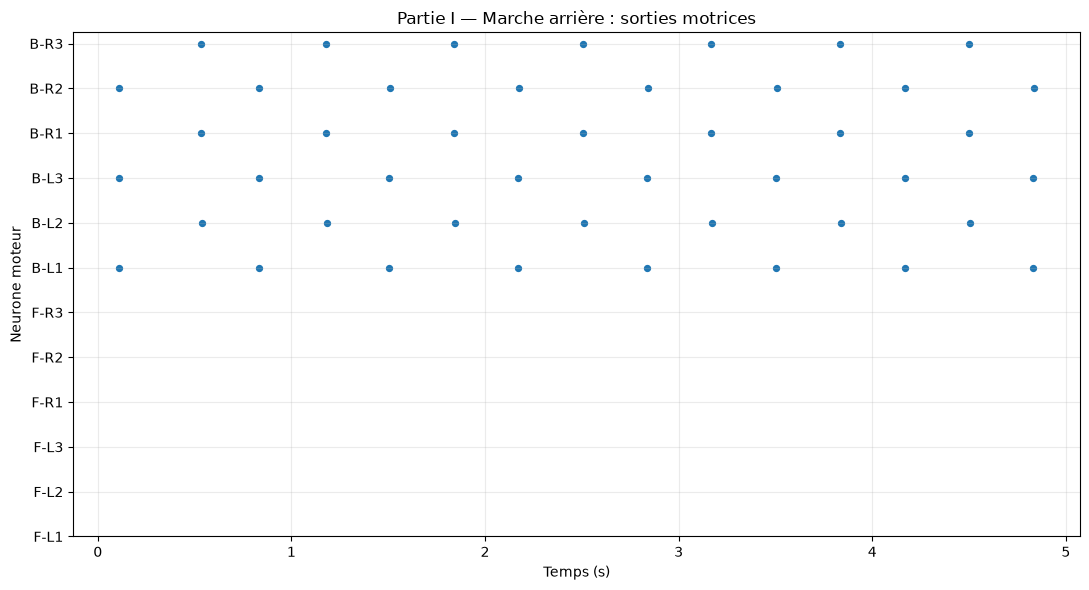

In [13]:

backward = simulate_locomotion(
    n_pairs=3,
    duration=5.0,
    left_freq=2.0,
    right_freq=2.0,
    left_direction=-1,
    right_direction=-1,
    sensor_control=False,
    record_state=False,
)

plot_motor_raster(
    backward,
    title="Partie I — Marche arrière : sorties motrices",
    save_name="03_backward_motor.png",
)


Lors de la marche arrière, seuls les motoneurones `Backward` produisent des spikes. Les motoneurones `Forward` restent silencieux.

Le rythme des commandes reste périodique et conserve l'alternance imposée par les CPG. La différence avec la marche avant ne provient donc pas d'une modification du rythme locomoteur, mais du choix de la voie prémotrice active.

Le fonctionnement peut être résumé par :

$$
CPG
\rightarrow
PM_B
\rightarrow
B
$$

Ce résultat montre que la même architecture CPG peut produire une marche avant ou arrière simplement en sélectionnant une voie prémotrice différente.

## 8. Variation de la vitesse

,fréquence_cible_hz,fréquence_mesurée_gauche_hz,fréquence_mesurée_droite_hz
0,1.2,0.75,0.75
1,2.0,1.50,1.50
2,3.0,2.25,2.25


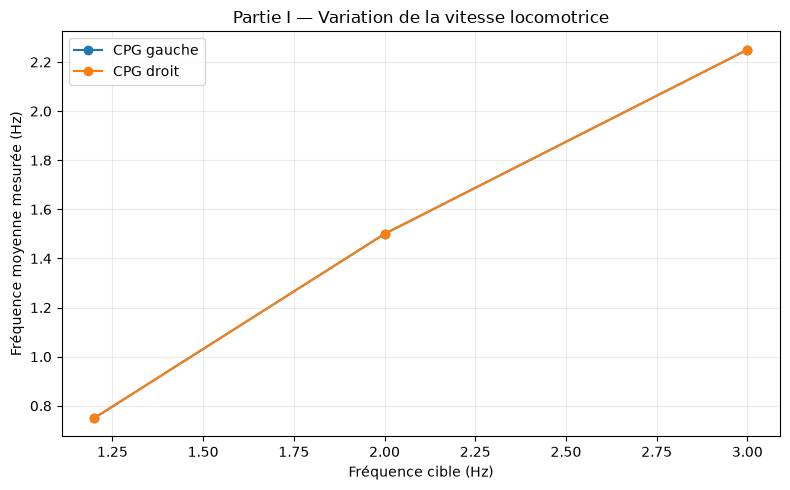

In [14]:

speed_rows = []

for target_freq in [1.2, 2.0, 3.0]:
    res = simulate_locomotion(
        n_pairs=3,
        duration=5.0,
        left_freq=target_freq,
        right_freq=target_freq,
        left_direction=+1,
        right_direction=+1,
        sensor_control=False,
        record_state=False,
    )

    rates = cpg_side_rates(
        res,
        t_start=1.0,
        t_end=5.0,
    )

    speed_rows.append({
        "fréquence_cible_hz": target_freq,
        "fréquence_mesurée_gauche_hz": rates["left_hz"],
        "fréquence_mesurée_droite_hz": rates["right_hz"],
    })

speed_df = pd.DataFrame(speed_rows)
display(speed_df)

plt.figure(figsize=(8, 5))
plt.plot(
    speed_df["fréquence_cible_hz"],
    speed_df["fréquence_mesurée_gauche_hz"],
    marker="o",
    label="CPG gauche",
)
plt.plot(
    speed_df["fréquence_cible_hz"],
    speed_df["fréquence_mesurée_droite_hz"],
    marker="o",
    label="CPG droit",
)
plt.xlabel("Fréquence cible (Hz)")
plt.ylabel("Fréquence moyenne mesurée (Hz)")
plt.title("Partie I — Variation de la vitesse locomotrice")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "04_speed_response.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


Pour effectuer une rotation vers la gauche, les deux côtés du corps reçoivent des commandes motrices opposées :

$$
\text{gauche} = \mathrm{Backward}
$$

$$
\text{droite} = \mathrm{Forward}
$$

Le graphe moteur confirme ce fonctionnement. Les motoneurones `B-L1`, `B-L2` et `B-L3` sont actifs du côté gauche, tandis que les motoneurones `F-R1`, `F-R2` et `F-R3` sont actifs du côté droit.

Les voies opposées restent silencieuses.

Ainsi, les deux côtés produisent des mouvements de direction opposée :

$$
\text{gauche recule}
\qquad
\text{droite avance}
$$

Cette opposition des commandes permet de produire une rotation sur place vers la gauche tout en conservant le rythme locomoteur généré par les CPG.

## 9. Rotation sur place

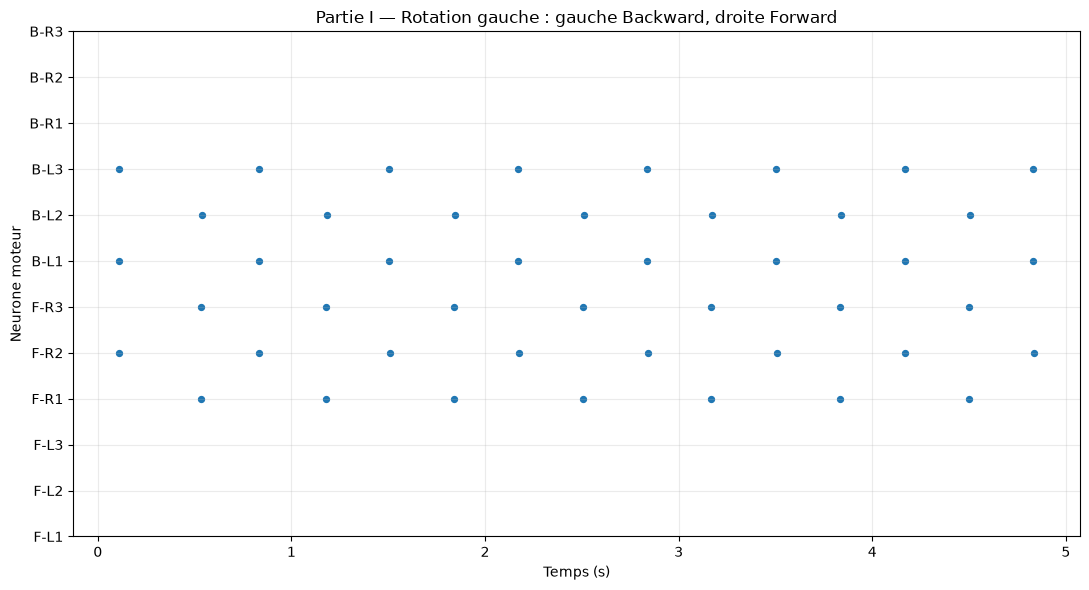

In [35]:

rotation_left = simulate_locomotion(
    n_pairs=3,
    duration=5.0,
    left_freq=2.0,
    right_freq=2.0,
    left_direction=-1,
    right_direction=+1,
    sensor_control=False,
    record_state=False,
)

plot_motor_raster(
    rotation_left,
    title="Partie I — Rotation gauche : gauche Backward, droite Forward",
    save_name="05_rotation_left_motor.png",
)


Pour effectuer une rotation vers la gauche, les deux côtés du corps reçoivent des commandes motrices opposées :

$$
\text{gauche} = \mathrm{Backward}
$$

$$
\text{droite} = \mathrm{Forward}
$$

Le graphe moteur confirme ce fonctionnement. Les motoneurones `B-L1`, `B-L2` et `B-L3` sont actifs du côté gauche, tandis que les motoneurones `F-R1`, `F-R2` et `F-R3` sont actifs du côté droit.

Les voies opposées restent silencieuses.

Ainsi, les deux côtés produisent des mouvements de direction opposée :

$$
\text{gauche recule}
\qquad
\text{droite avance}
$$

Cette opposition des commandes permet de produire une rotation sur place vers la gauche tout en conservant le rythme locomoteur généré par les CPG.

## 10. Déplacement en cercle

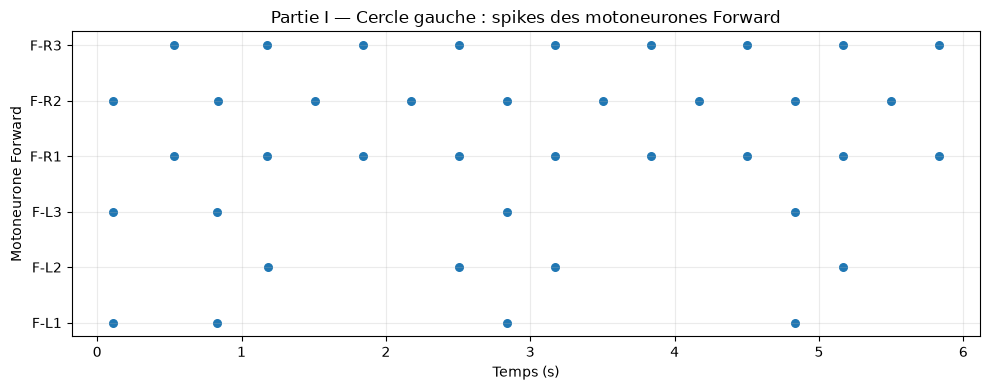

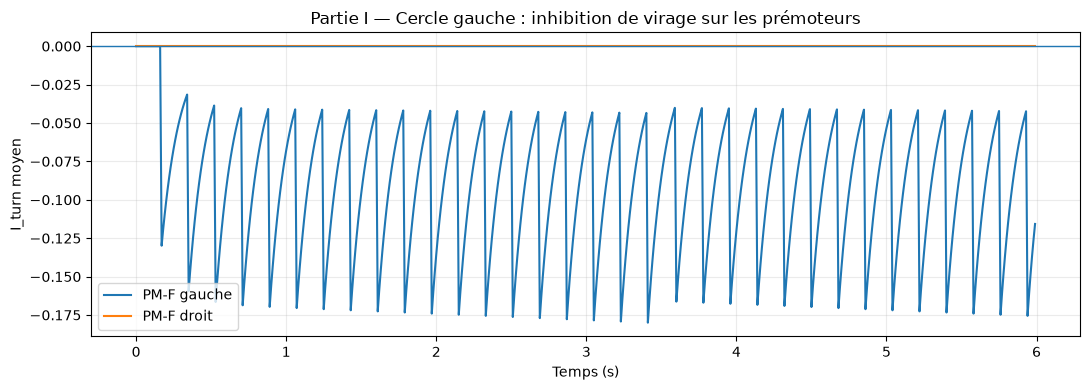

,left_forward_hz,right_forward_hz
0,0.533333,1.533333


In [49]:

circle_left = simulate_locomotion(
    n_pairs=3,
    duration=6.0,

    # Même rythme CPG des deux côtés
    left_freq=2.0,
    right_freq=2.0,

    # Marche avant
    left_direction=+1,
    right_direction=+1,

    # Activation de TURN_LEFT
    turn_command="left",
    turn_drive=1.25,
    turn_step=0.14,
    
    sensor_control=False,
    record_state=True,
)


plot_forward_motor_raster(
    circle_left,
    title="Partie I — Cercle gauche : spikes des motoneurones Forward",
    save_name="06d_circle_left_forward_motor_raster.png",
)

plot_premotor_turn_modulation(
    circle_left,
    title="Partie I — Cercle gauche : inhibition de virage sur les prémoteurs",
    save_name="06c_circle_left_turn_modulation.png",
)

circle_motor_rates = motor_forward_side_rates(
    circle_left,
    t_start=1.0,
    t_end=6.0,
)

display(pd.DataFrame([circle_motor_rates]))




Pour produire un déplacement en cercle vers la gauche, la fréquence des CPG gauche et droit n'est plus modifiée. Le rythme locomoteur reste donc généré normalement par les CPG afin de préserver l'alternance entre les groupes.

Le virage est produit au niveau prémoteur. Le neurone central `TURN_LEFT` inhibe temporairement les prémoteurs Forward du côté gauche par l'intermédiaire de la variable $I_{\mathrm{turn}}$.

Le graphique de $I_{\mathrm{turn}}$ montre que :

$$
I_{\mathrm{turn,gauche}} < 0
$$

alors que :

$$
I_{\mathrm{turn,droit}} \approx 0
$$

Les prémoteurs Forward gauches sont donc moins excitables que les prémoteurs Forward droits.

Cette différence apparaît ensuite dans les sorties motrices. La fréquence moyenne mesurée est d'environ :

$$
f_{\mathrm{Forward,gauche}}
=
0.53\ \mathrm{Hz}
$$

contre :

$$
f_{\mathrm{Forward,droit}}
=
1.53\ \mathrm{Hz}
$$

Ainsi :

$$
f_{\mathrm{Forward,gauche}}
<
f_{\mathrm{Forward,droit}}
$$

Le côté droit produit donc davantage de commandes Forward que le côté gauche. Cette asymétrie des sorties motrices permet de courber la trajectoire vers la gauche sans modifier directement le rythme des CPG.

Le résultat confirme donc que le virage est maintenant généré au niveau prémoteur et moteur, tandis que le réseau CPG conserve son rôle de générateur du rythme locomoteur.


# PARTIE II — Système pseudo-autonome

Le scénario suivant montre **dans une seule simulation** plusieurs événements successifs :

1. obstacle à droite \(\rightarrow\) `TURN_LEFT` ;
2. obstacle à gauche \(\rightarrow\) `TURN_RIGHT` ;
3. obstacle frontal \(\rightarrow\) `BACKWARD` ;
4. stimulation arrière \(\rightarrow\) `ACCELERATE`.

Les obstacles latéraux se rapprochent progressivement afin de montrer l'effet de l'intensité.


In [50]:

autonomous_events = [
    # Obstacle à droite qui se rapproche
    {
        "side": "right",
        "start": 2.0,
        "end": 4.0,
        "distance_start_cm": 65.0,
        "distance_end_cm": 20.0,
    },

    # Obstacle à gauche qui se rapproche
    {
        "side": "left",
        "start": 5.0,
        "end": 7.0,
        "distance_start_cm": 65.0,
        "distance_end_cm": 20.0,
    },

    # Obstacle frontal
    {
        "side": "front",
        "start": 8.0,
        "end": 10.0,
        "distance_start_cm": 55.0,
        "distance_end_cm": 15.0,
    },

    # Stimulation arrière
    {
        "side": "rear",
        "start": 11.0,
        "end": 13.0,
        "distance_start_cm": 60.0,
        "distance_end_cm": 15.0,
    },
]

autonomous = simulate_locomotion(
    n_pairs=3,
    duration=14.0,
    left_freq=2.0,
    right_freq=2.0,
    sensor_control=True,
    sensor_events=autonomous_events,
    record_state=True,
    report=False,
)

print(
    f"Simulation terminée en "
    f"{autonomous['elapsed_seconds']:.3f} s."
)


Simulation terminée en 47.519 s.


## 11. Distances et fréquences sensorielle

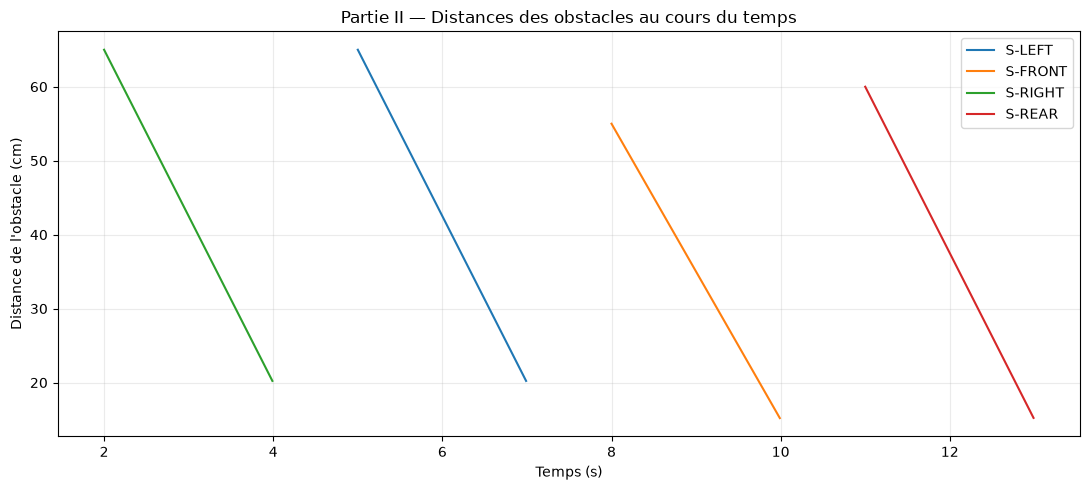

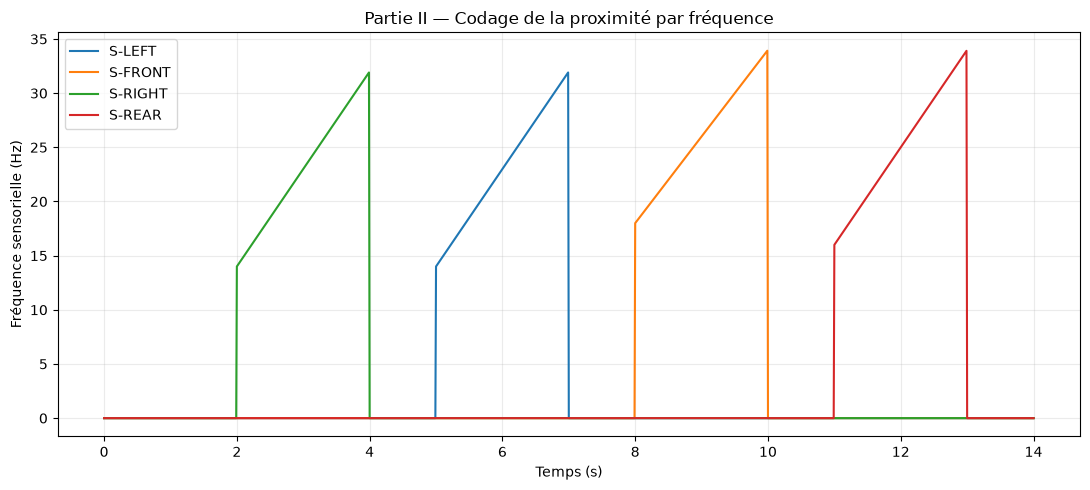

In [18]:

plot_sensor_distances(
    autonomous,
    title="Partie II — Distances des obstacles au cours du temps",
    save_name="10_auto_distances.png",
)

plot_sensor_rates(
    autonomous,
    title="Partie II — Codage de la proximité par fréquence",
    save_name="11_auto_sensor_rates.png",
)


Le premier graphique représente la distance des différents obstacles au cours du temps. Quatre situations successives sont simulées :

- entre environ $2$ et $4$ s : un obstacle se rapproche du côté droit ;
- entre environ $5$ et $7$ s : un obstacle se rapproche du côté gauche ;
- entre environ $8$ et $10$ s : un obstacle se rapproche à l'avant ;
- entre environ $11$ et $13$ s : une stimulation se rapproche à l'arrière.

Dans chaque cas, la distance diminue progressivement.

Le second graphique montre la fréquence sensorielle obtenue à partir de cette distance. Lorsque l'obstacle se rapproche, la fréquence du neurone sensoriel correspondant augmente.

On vérifie donc bien la relation :

$$
d \downarrow
\quad\Rightarrow\quad
f_{\mathrm{sensoriel}} \uparrow
$$

Par exemple, lorsque l'obstacle droit se rapproche entre $2$ et $4$ s, la fréquence de `S-RIGHT` augmente progressivement. Le même comportement est observé pour les autres capteurs.

Ces résultats montrent que la distance de l'obstacle est correctement transformée en une information neuronale codée par la fréquence de décharge.

## 12. Activité des neurones sensoriels

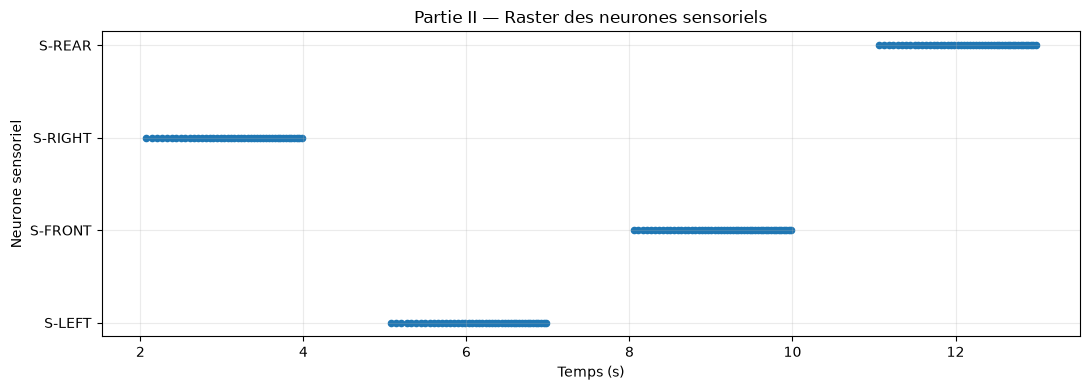

In [19]:

plot_sensor_raster(
    autonomous,
    title="Partie II — Raster des neurones sensoriels",
    save_name="12_auto_sensor_raster.png",
)


Le graphe sensoriel montre que chaque neurone sensoriel devient actif uniquement pendant la période où un stimulus est présent dans sa zone de détection.

On observe successivement :

- `S-RIGHT` actif entre environ $2$ et $4$ s ;
- `S-LEFT` actif entre environ $5$ et $7$ s ;
- `S-FRONT` actif entre environ $8$ et $10$ s ;
- `S-REAR` actif entre environ $11$ et $13$ s.

Les spikes deviennent également plus rapprochés lorsque le stimulus se rapproche, ce qui correspond à l'augmentation de la fréquence sensorielle observée précédemment.

Le raster confirme donc que les neurones sensoriels transforment correctement l'information de distance en trains de spikes.

## 13. Activité des neurones centraux de décision

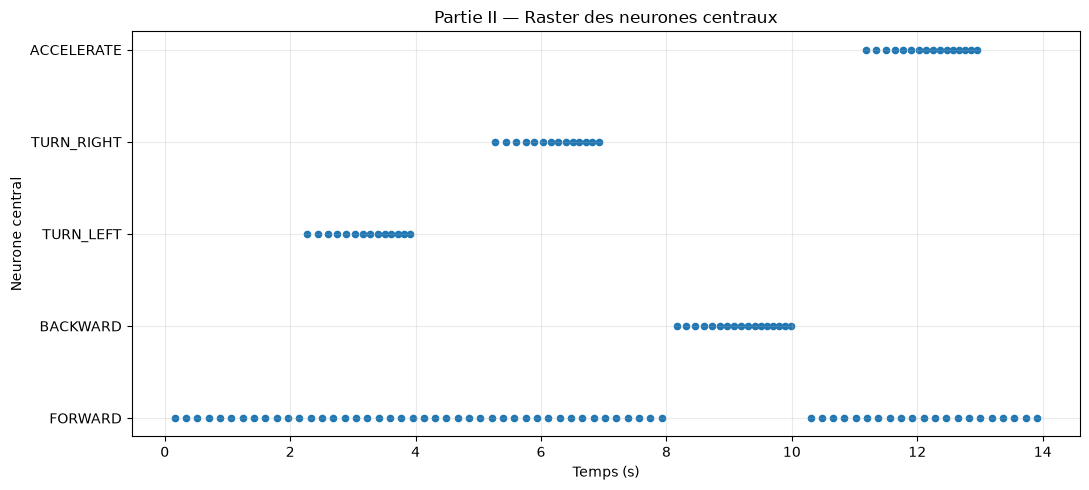

,FORWARD,BACKWARD,TURN_LEFT,TURN_RIGHT,ACCELERATE
0,4.642857,1.214286,1.0,1.0,1.142857


In [20]:

plot_decision_raster(
    autonomous,
    title="Partie II — Raster des neurones centraux",
    save_name="13_auto_decision_raster.png",
)

decision_rate_table = pd.DataFrame(
    [decision_rates(autonomous)]
)

display(decision_rate_table)


Le graphe des neurones centraux montre que les informations sensorielles déclenchent les comportements attendus.

Au début de la simulation, `FORWARD` est actif spontanément et maintient la marche avant en l'absence de danger.

Lorsqu'un obstacle apparaît à droite, `S-RIGHT` active `TURN_LEFT`. À l'inverse, lorsqu'un obstacle apparaît à gauche, `S-LEFT` active `TURN_RIGHT`.

Entre environ $8$ et $10$ s, l'obstacle frontal active `BACKWARD`. Pendant cette période, l'activité de `FORWARD` disparaît, ce qui montre que la marche arrière prend temporairement la priorité sur la marche avant.

Enfin, la stimulation arrière active `ACCELERATE` entre environ $11$ et $13$ s.

La séquence obtenue est donc cohérente avec l'architecture choisie :

$$
S_{\mathrm{RIGHT}}
\rightarrow
\mathrm{TURN\_LEFT}
$$

$$
S_{\mathrm{LEFT}}
\rightarrow
\mathrm{TURN\_RIGHT}
$$

$$
S_{\mathrm{FRONT}}
\rightarrow
\mathrm{BACKWARD}
$$

$$
S_{\mathrm{REAR}}
\rightarrow
\mathrm{ACCELERATE}
$$

Ces résultats montrent que la couche centrale joue bien son rôle de sélection du comportement à partir des informations sensorielles.

## 14. Sélection dynamique Forward / Backward

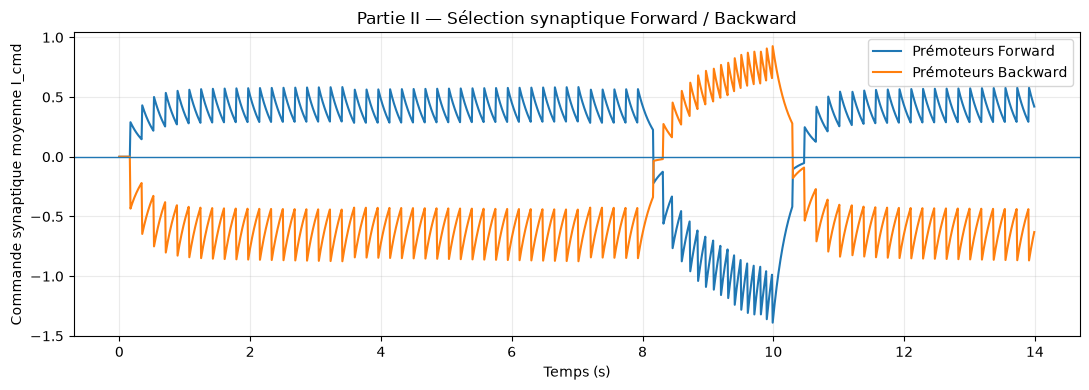

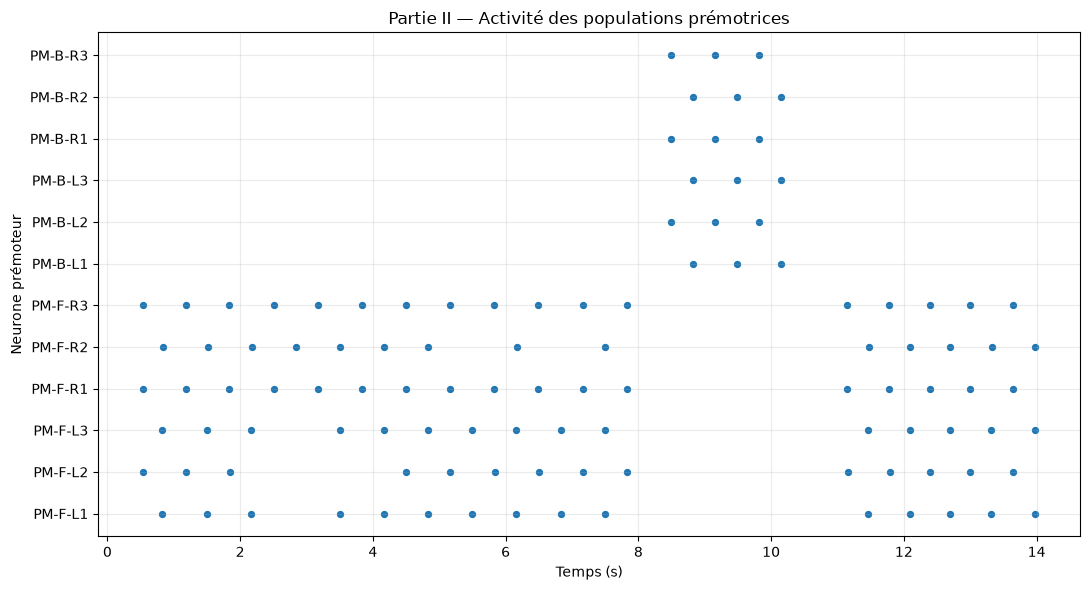

In [21]:

plot_premotor_selection(
    autonomous,
    title="Partie II — Sélection synaptique Forward / Backward",
    save_name="14_auto_premotor_selection.png",
)

plot_premotor_raster(
    autonomous,
    title="Partie II — Activité des populations prémotrices",
    save_name="14b_auto_premotor_raster.png",
)


Le premier graphique représente la commande synaptique moyenne $I_{\mathrm{cmd}}$ reçue par les populations prémotrices Forward et Backward.

En marche normale, la population Forward reçoit une commande positive, tandis que la population Backward reçoit une commande négative. La voie Forward est donc favorisée.

Lors de l'apparition de l'obstacle frontal, entre environ $8$ et $10$ s, cette situation s'inverse :

$$
I_{\mathrm{cmd,Forward}} < 0
$$

et :

$$
I_{\mathrm{cmd,Backward}} > 0
$$

La voie Forward devient donc inhibée tandis que la voie Backward devient favorisée.

Le raster prémoteur confirme cette transition. Avant l'obstacle frontal, seuls les prémoteurs Forward produisent des spikes. Pendant la phase de recul, l'activité bascule vers les prémoteurs Backward. Après disparition de l'obstacle, l'activité Forward reprend.

Les oscillations en dents de scie de $I_{\mathrm{cmd}}$ correspondent aux apports successifs produits par les spikes des neurones centraux, suivis de la décroissance progressive de la commande synaptique.

Ce résultat montre que le passage Forward / Backward est obtenu par une compétition neuronale continue et non par une variable logique de type `gate`.

## 15. Modulation de la vitesse gauche / droite

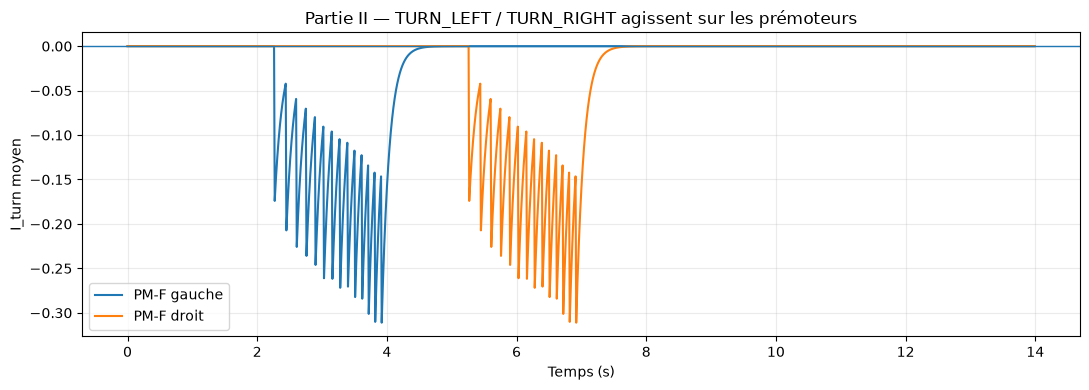

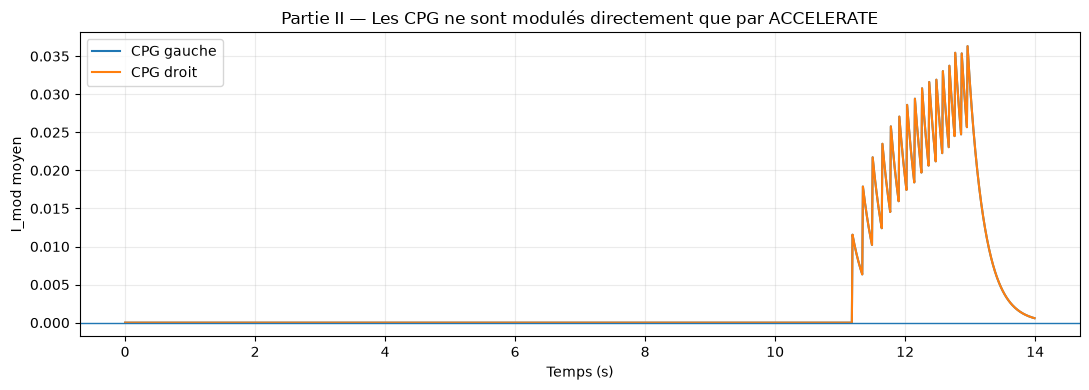

In [22]:

plot_premotor_turn_modulation(
    autonomous,
    title="Partie II — TURN_LEFT / TURN_RIGHT agissent sur les prémoteurs",
    save_name="15_auto_premotor_turn.png",
)

plot_cpg_modulation(
    autonomous,
    title="Partie II — Les CPG ne sont modulés directement que par ACCELERATE",
    save_name="15b_auto_cpg_acceleration.png",
)


Le premier graphique montre l'action de `TURN_LEFT` et `TURN_RIGHT` sur les prémoteurs Forward.

Lorsqu'un obstacle est détecté à droite, `TURN_LEFT` devient actif et rend $I_{\mathrm{turn}}$ négatif uniquement pour les prémoteurs Forward gauches. Le côté gauche transmet alors moins de commandes Forward, ce qui permet de courber la trajectoire vers la gauche.

Inversement, lorsqu'un obstacle est détecté à gauche, `TURN_RIGHT` inhibe les prémoteurs Forward droits.

Ainsi, les virages sont produits au niveau prémoteur sans modifier directement le rythme des CPG.

Le second graphique montre que $I_{\mathrm{mod}}$ des CPG reste nul pendant les phases de virage. Il n'augmente qu'entre environ $11$ et $13$ s, lorsque le neurone `ACCELERATE` est activé par la stimulation arrière.

Les CPG gauche et droit reçoivent alors la même modulation positive.

Ces résultats confirment donc la séparation fonctionnelle choisie :

$$
\mathrm{TURN\_LEFT/RIGHT}
\rightarrow
\text{prémoteurs}
$$

tandis que :

$$
\mathrm{ACCELERATE}
\rightarrow
\text{CPG}
$$

Cette organisation permet de produire un virage sans perturber directement l'alternance des groupes locomoteurs.

## 16. Activité des CPG pendant le comportement autonome

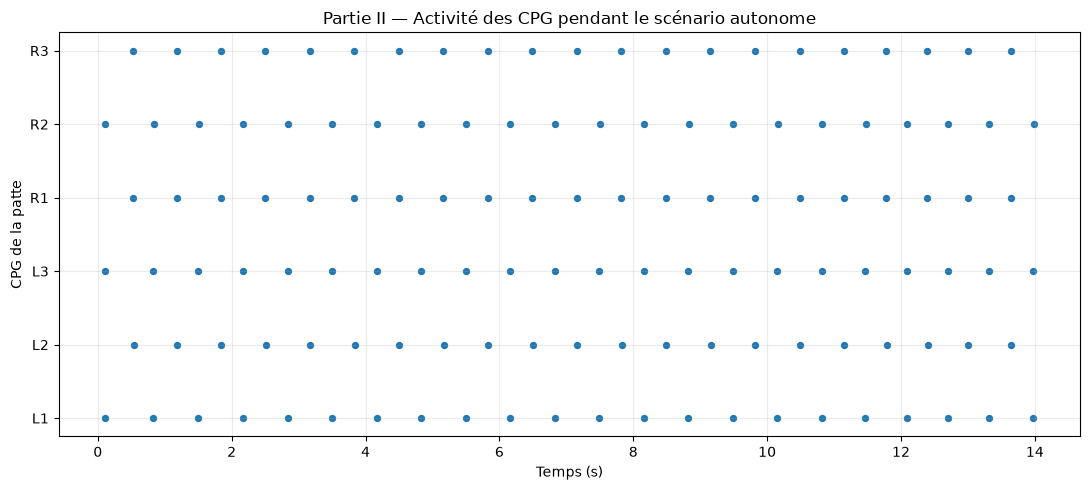

In [23]:

plot_cpg_raster(
    autonomous,
    title="Partie II — Activité des CPG pendant le scénario autonome",
    save_name="16_auto_cpg_raster.png",
)


## 17. Sorties motrices finales

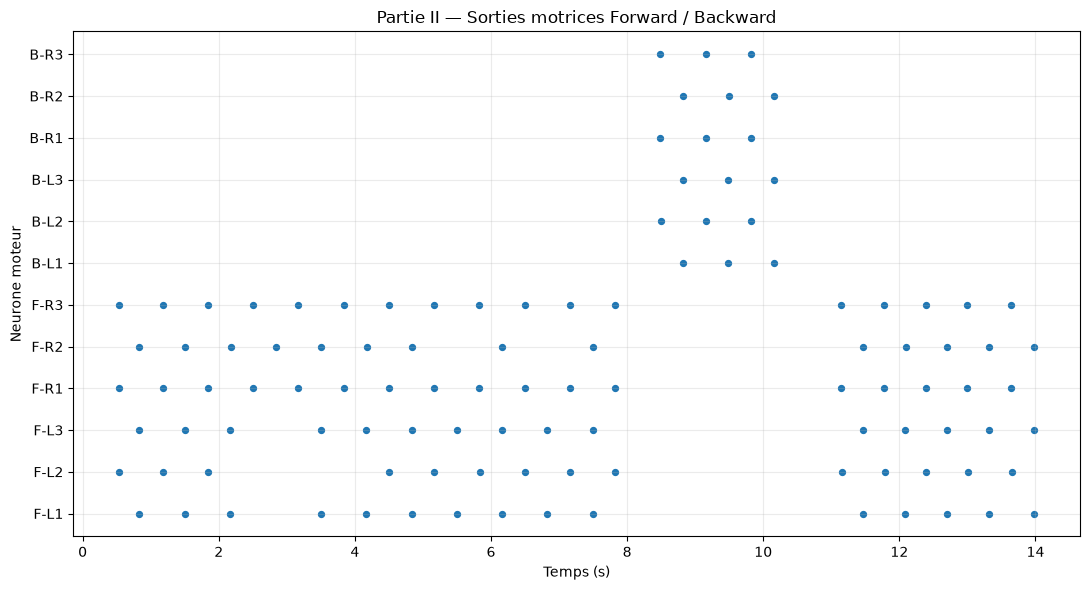

In [24]:

plot_motor_raster(
    autonomous,
    title="Partie II — Sorties motrices Forward / Backward",
    save_name="17_auto_motor_raster.png",
)


Le graphe moteur montre les commandes finales produites par le réseau.

Pendant la majorité de la simulation, les motoneurones Forward sont actifs, ce qui correspond au comportement normal de marche avant.

Entre environ $8$ et $10$ s, lorsque l'obstacle frontal est détecté, les sorties Forward disparaissent et les motoneurones Backward deviennent actifs.

On observe donc une transition claire :

$$
\mathrm{Forward}
\rightarrow
\mathrm{Backward}
\rightarrow
\mathrm{Forward}
$$

La marche arrière est temporaire : lorsque le stimulus frontal disparaît, la voie Forward redevient dominante.

Ce résultat confirme que la décision prise par les neurones centraux se propage correctement jusqu'aux neurones prémoteurs puis aux sorties motrices finales.


# 18. Expérience dédiée : influence de la distance

Cette expérience vérifie maintenant deux choses :

1. un obstacle droit plus proche active davantage `TURN_LEFT` ;
2. `TURN_LEFT` réduit les **sorties motrices Forward gauches**, sans imposer
   une nouvelle fréquence aux CPG.

On mesure donc :

- la fréquence de `TURN_LEFT` ;

On s'attend à :
$$
[
d_{\text{droite}}\downarrow
\Rightarrow
f_{TURN\_LEFT}\uparrow
\Rightarrow
\text{moins de sorties Forward à gauche}
]
$$

In [55]:

distance_tests = [70, 55, 40, 25, 15]

intensity_rows = []

for d in distance_tests:
    res = simulate_locomotion(
        n_pairs=3,
        duration=4.0,
        left_freq=2.0,
        right_freq=2.0,
        sensor_control=True,
        sensor_events=[
            {
                "side": "right",
                "start": 0.5,
                "end": 3.5,
                "distance_cm": d,
            }
        ],
        record_state=False,
    )

    dec = decision_rates(
        res,
        t_start=1.0,
        t_end=3.5,
    )

    cpg_sides = cpg_side_rates(
        res,
        t_start=1.0,
        t_end=3.5,
    )

    motor_sides = motor_forward_side_rates(
        res,
        t_start=1.0,
        t_end=3.5,
    )

    intensity_rows.append({
        "distance_cm": d,
        "sensor_rate_hz": float(
            distance_to_sensor_rate(d)
        ),
        "turn_left_rate_hz": dec["TURN_LEFT"],


        "motor_forward_left_hz": motor_sides["left_forward_hz"],
        "motor_forward_right_hz": motor_sides["right_forward_hz"],
        "motor_asymmetry_hz": (
            motor_sides["right_forward_hz"]
            - motor_sides["left_forward_hz"]
        ),
    })

intensity_df = pd.DataFrame(intensity_rows)
display(intensity_df)


,distance_cm,sensor_rate_hz,turn_left_rate_hz,motor_forward_left_hz,motor_forward_right_hz,motor_asymmetry_hz
0,70,12.0,0.0,1.333333,1.466667,0.133333
1,55,18.0,6.0,1.066667,1.466667,0.400000
2,40,24.0,8.0,0.666667,1.466667,0.800000
3,25,30.0,10.0,0.266667,1.466667,1.200000
4,15,34.0,11.2,0.266667,1.466667,1.200000


Le tableau montre l'effet de la distance d'un obstacle situé à droite sur toute la chaîne sensorimotrice.

Lorsque la distance diminue, la fréquence sensorielle augmente :

$$
70\ \mathrm{cm}
\rightarrow
12\ \mathrm{Hz}
$$

jusqu'à :

$$
15\ \mathrm{cm}
\rightarrow
34\ \mathrm{Hz}
$$

Cette augmentation de l'activité sensorielle entraîne une augmentation de la fréquence du neurone central `TURN_LEFT`.

En parallèle, la fréquence des sorties Forward gauches diminue fortement, tandis que la fréquence des sorties Forward droites reste pratiquement constante.

Par conséquent, l'asymétrie motrice :

$$
f_{\mathrm{Forward,droit}}
-
f_{\mathrm{Forward,gauche}}
$$

augmente lorsque l'obstacle se rapproche.

Le système adapte donc progressivement l'intensité de sa réponse au niveau de danger détecté, plutôt que de produire une simple commande binaire de virage.

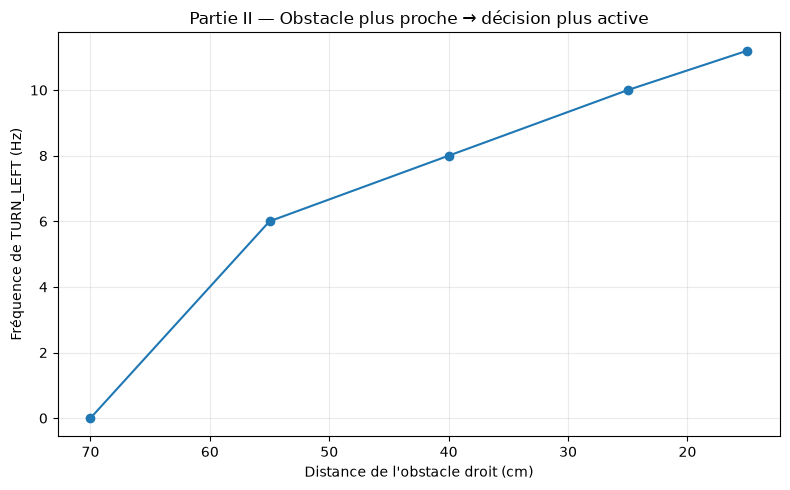

In [26]:

plt.figure(figsize=(8, 5))
plt.plot(
    intensity_df["distance_cm"],
    intensity_df["turn_left_rate_hz"],
    marker="o",
)
plt.gca().invert_xaxis()
plt.xlabel("Distance de l'obstacle droit (cm)")
plt.ylabel("Fréquence de TURN_LEFT (Hz)")
plt.title("Partie II — Obstacle plus proche → décision plus active")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "18_distance_vs_turn_left.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


Ce graphique montre que la fréquence de décharge du neurone central `TURN_LEFT` augmente lorsque l'obstacle situé à droite se rapproche.

Lorsque l'obstacle est éloigné, l'activité de `TURN_LEFT` est faible ou nulle. À mesure que la distance diminue, sa fréquence augmente progressivement.

On observe donc la relation :

$$
d_{\mathrm{obstacle}} \downarrow
\quad\Rightarrow\quad
f_{\mathrm{TURN\_LEFT}} \uparrow
$$

Cette relation résulte directement du codage sensoriel par fréquence : un obstacle plus proche augmente l'activité de `S-RIGHT`, qui excite davantage `TURN_LEFT`.

Le réseau central ne se contente donc pas de détecter la présence d'un obstacle : l'intensité de la décision dépend également de sa proximité.

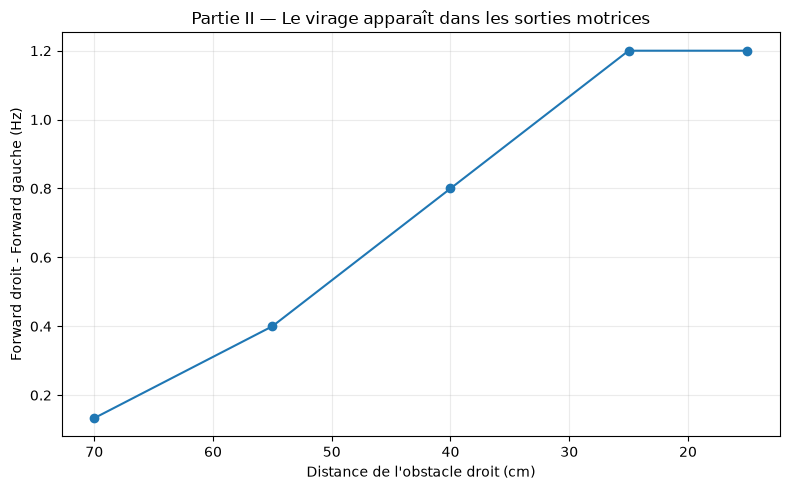

In [53]:

plt.figure(figsize=(8, 5))
plt.plot(
    intensity_df["distance_cm"],
    intensity_df["motor_asymmetry_hz"],
    marker="o",
)
plt.gca().invert_xaxis()
plt.xlabel("Distance de l'obstacle droit (cm)")
plt.ylabel("Forward droit - Forward gauche (Hz)")
plt.title("Partie II — Le virage apparaît dans les sorties motrices")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "19_distance_vs_motor_turn_strength.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


Ce graphique représente l'asymétrie entre les sorties Forward droite et gauche :

$$
\Delta f
=
f_{\mathrm{Forward,droit}}
-
f_{\mathrm{Forward,gauche}}
$$

Lorsque l'obstacle droit est éloigné, cette différence est faible : les deux côtés produisent presque autant de commandes Forward.

Lorsque l'obstacle se rapproche, `TURN_LEFT` devient plus actif et inhibe davantage les prémoteurs Forward gauches. La fréquence motrice gauche diminue donc, tandis que la fréquence droite reste relativement stable.

L'asymétrie augmente ainsi progressivement jusqu'à atteindre environ $1.2$ Hz.

On observe ensuite un plateau pour les distances les plus faibles. Cela indique une saturation de la réponse : les prémoteurs gauches sont déjà fortement inhibés et une augmentation supplémentaire de l'activité de `TURN_LEFT` ne peut plus réduire beaucoup plus leur fréquence.

Le graphique montre donc que :

$$
\text{obstacle plus proche}
\Rightarrow
\text{virage plus marqué}
$$

jusqu'à saturation du mécanisme prémoteur.


# 19. Généralisation à 200 paires de pattes

L'architecture doit dépendre d'une seule variable structurelle : `n_pairs`.

Le test suivant vérifie plusieurs  :
$$
[
20,\;50,\;100,\;200\text{ paires}
]
$$


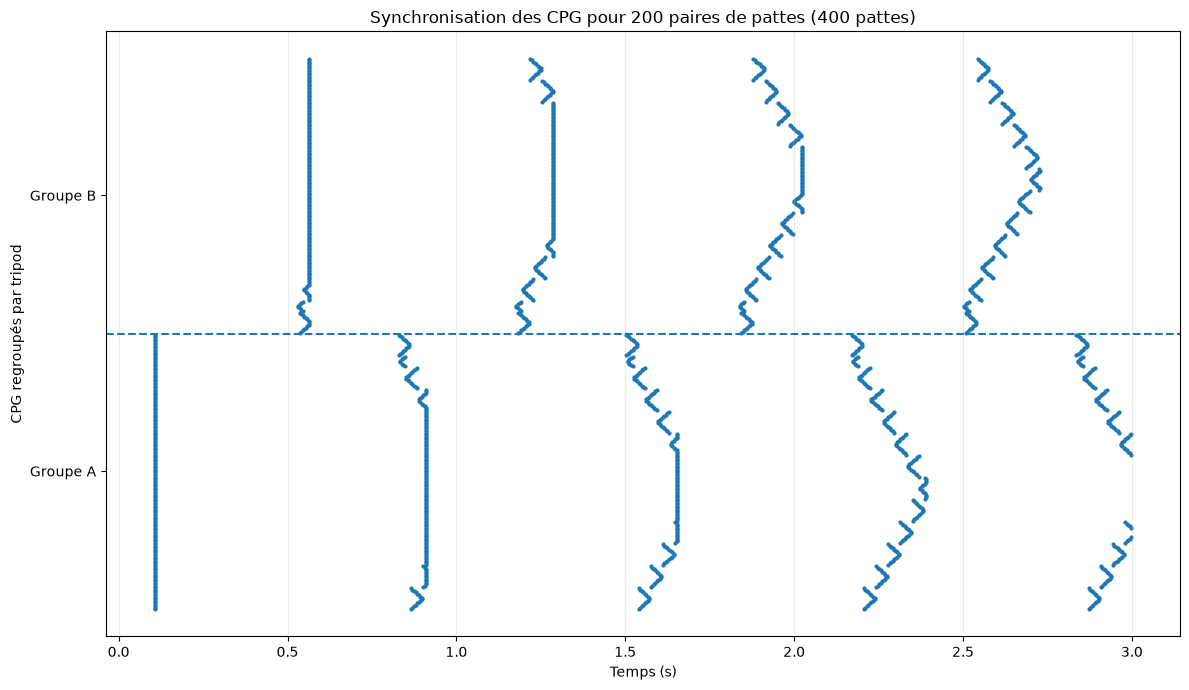

In [52]:
# ============================================================
# Généralisation : synchronisation avec 200 paires de pattes
# ============================================================

large_network = simulate_locomotion(
    n_pairs=200,       # 200 paires = 400 pattes
    duration=3.0,
    left_freq=2.0,
    right_freq=2.0,
    left_direction=+1,
    right_direction=+1,
    sensor_control=False,
    record_state=False,
    report=False,
)

# Récupération des spikes
spike_t = large_network["cpg_t"]
spike_i = large_network["cpg_i"]

# Groupe de chaque CPG : 0 = A, 1 = B
groups = large_network["groups"]

n_legs = large_network["n_legs"]

# ------------------------------------------------------------
# On réorganise les neurones pour afficher :
# tous les neurones A ensemble,
# puis tous les neurones B ensemble.
# ------------------------------------------------------------

order = np.argsort(groups)

# rank[i] = nouvelle position verticale du neurone i
rank = np.empty(n_legs, dtype=int)
rank[order] = np.arange(n_legs)

# Nouvelle position verticale de chaque spike
spike_y = rank[spike_i]

# Nombre de neurones du groupe A
n_group_A = np.sum(groups == 0)

# ------------------------------------------------------------
# Raster
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

plt.scatter(
    spike_t,
    spike_y,
    s=4,
)

# Séparation visuelle entre les deux groupes
plt.axhline(
    n_group_A - 0.5,
    linestyle="--",
    linewidth=1.5,
)

plt.xlabel("Temps (s)")
plt.ylabel("CPG regroupés par tripod")

plt.yticks(
    [
        n_group_A / 2,
        n_group_A + (n_legs - n_group_A) / 2,
    ],
    [
        "Groupe A",
        "Groupe B",
    ],
)

plt.title(
    "Synchronisation des CPG pour 200 paires de pattes "
    "(400 pattes)"
)

plt.grid(
    axis="x",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "20_large_network_synchronization.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

Cette simulation teste la généralisation du réseau à $200$ paires de pattes, soit $400$ CPG.

Les CPG ont été regroupés selon leur appartenance aux groupes locomoteurs A et B.

On observe que l'activité des deux groupes reste globalement alternée au cours du temps : lorsqu'un groupe est actif, l'autre est décalé dans le temps.

Cependant, contrairement au cas à six pattes, tous les CPG d'un même groupe ne déchargent plus exactement au même instant. Les formes inclinées observées sur le raster indiquent l'apparition de décalages de phase entre neurones.

Ce phénomène est cohérent avec l'architecture distribuée utilisée : les connexions entre CPG sont locales et l'information de synchronisation se propage progressivement dans un réseau devenu beaucoup plus grand.

Le résultat montre donc deux propriétés importantes :

- l'alternance globale entre les groupes A et B reste présente ;
- la synchronisation exacte à l'intérieur d'un groupe diminue lorsque le réseau devient très grand.

La généralisation conserve ainsi une coordination locomotrice collective, même si une propagation en onde de l'activité apparaît à grande échelle.


# 21. Limites et points à discuter

Quelques limites qu'il est utile de mentionner dans la discussion :

- le modèle représente les **instants de commande**, pas la mécanique réelle de la patte ;
- les capteurs sont simulés par une distance imposée et non par un environnement physique 3D ;
- le virage est produit par une asymétrie de fréquence CPG gauche/droite ;
- les paramètres synaptiques ont été choisis pour produire un comportement démontrable et doivent être justifiés expérimentalement ;
- les comportements simultanés complexes (plusieurs obstacles en même temps) nécessiteraient une couche de décision plus élaborée ;
- le couplage local favorise la scalabilité mais ne garantit pas mathématiquement une synchronisation parfaite dans toutes les conditions.

Ces limites sont compatibles avec l'objectif du projet : étudier une architecture de commande neuronale et démontrer son fonctionnement par simulation.
